# Video Games Reviews: Sentiment Classification

## 1. Project Overview

### Problem Context
A marketplace with millions of product reviews cannot read every review by hand. Negative reviews are the most urgent ones: they point to broken products, shipping problems or misleading descriptions, and the sooner the product team sees them, the sooner they can act. A model that labels each new review as negative or positive makes it possible to route complaints to the right people without reading each review.

This project uses Amazon Reviews 2023, category Video Games, and keeps only reviews written up to 31 December 2019, as the assignment requires. The input is the review title and the review text. The label comes from the star rating: ratings 1 and 2 are negative, ratings 4 and 5 are positive, and rating 3 is dropped because it is ambiguous.

### Objective
Build a classifier that recognises negative and positive reviews equally well, not one that is only good on the larger class. Most reviews are positive, so a model that always answers positive would look accurate and still be useless for finding complaints.

### Evaluation Metric
The primary metric is **macro-F1**, the mean of the F1 score of the negative class and the F1 score of the positive class. Each class counts the same, no matter how many reviews it has. Precision, recall, the confusion matrix and the precision-recall curve of the negative class are reported as supporting evidence.

### Approach
1. Download the data and stream it to a compact file, so the large raw file is never loaded at once.
2. Audit the data, clean it with fixed rules, and explore it.
3. Decide the features, then compare a baseline against several models on the same validation scheme.
4. Choose the final model and decision threshold on validation data only.
5. Score the held-out test set once, at the end, and save the final model.

### Notebook Roadmap
| Section | Content |
|---|---|
| 1 | Project overview, setup and reproducibility |
| 2 | Dataset description, download and loading |
| 3 | Data quality assessment |
| 4 | Data preparation |
| 5 | Exploratory data analysis |
| 6 | Feature engineering |
| 7 | Baseline model |
| 8 | Model training |
| 9 | Model evaluation |
| 10 | Interpretation |
| 11 | Conclusion and recommendations |
| 12 | Saving and reloading the model |

### Setup & Reproducibility

In [89]:
import gc
import html
import json
import os
import platform
import re
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import pyarrow as pa
import pyarrow.parquet as pq
import sklearn
import torch
from huggingface_hub import hf_hub_download
from scipy import sparse
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from transformers import pipeline

SEED = 42
rng = np.random.default_rng(SEED)

DATA_DIR = Path('data')
MODEL_DIR = Path('models')
RAW_PATH = DATA_DIR / 'raw' / 'review_categories' / 'Video_Games.jsonl'
PARQUET_PATH = DATA_DIR / 'reviews_until_2019.parquet'
STATS_PATH = DATA_DIR / 'stream_stats.json'

CUTOFF = pd.Timestamp('2020-01-01', tz='UTC')
CUTOFF_MS = int(CUTOFF.timestamp() * 1000)

DATA_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_colwidth', 100)

print('python', platform.python_version(), '| pandas', pd.__version__,
      '| numpy', np.__version__, '| pyarrow', pa.__version__, '| scikit-learn', sklearn.__version__)

total_gb = psutil.virtual_memory().total / 1e9
if total_gb < 16:
    print(f'WARNING: this machine has {total_gb:.0f} GB of memory. The notebook needs about 16 GB; '
          'the full-period fits in Sections 6 and 7 may run out of memory.')


python 3.11.15 | pandas 3.1.1 | numpy 2.4.6 | pyarrow 26.0.1 | scikit-learn 1.9.1


## 2. Dataset Description and Source

The data is published by the McAuley Lab (University of California San Diego) as Amazon Reviews 2023.

Dataset Detail:
- Dataset Name              : Amazon Reviews 2023, category Video_Games
- Dataset Publisher         : McAuley Lab, UCSD
- Dataset Creators          : Yupeng Hou, Jiacheng Li, Zhankui He, An Yan, Xiusi Chen, Julian McAuley
- Project Page              : [https://amazon-reviews-2023.github.io](https://amazon-reviews-2023.github.io)
- Hugging Face              : [https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023](https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023)
- File Used                 : `raw/review_categories/Video_Games.jsonl`
- Reference                 : Hou et al. (2024), *Bridging Language and Items for Retrieval and Recommendation*
- Terms of Use              : see the dataset pages above

### 2.1 Dataset Description

Each line of the file is one review written as a JSON object. The file is large (several gigabytes), so it is read line by line and never loaded as a whole. Reviews written on or after 1 January 2020 are skipped while reading, so everything kept respects the assignment's cutoff of 31 December 2019. Rating 3 is **not** removed here. It stays in the stored data so that the audit in Section 3 can describe the full rating scale, and it is removed in Section 4.

Only the columns listed below are stored. The review images field is skipped because it is not used.

#### Data Dictionary

| Column | Description | Type | Role |
|---|---|---|---|
| `rating` | Star rating given by the user, from 1.0 to 5.0 | float | Source of the label |
| `title` | Title of the review | text | Model input |
| `text` | Body of the review | text | Model input |
| `timestamp` | Time of the review, in milliseconds since 1970-01-01 UTC | integer | Time split and cutoff |
| `helpful_vote` | Number of users who marked the review as helpful | integer | Analysis only, not a model input |
| `verified_purchase` | Whether the review comes from a verified purchase | boolean | Analysis only, not a model input |
| `parent_asin` | Identifier of the product (parent product) | text | Leakage checks and grouping |
| `asin` | Identifier of the product variant | text | Leakage checks |
| `user_id` | Identifier of the reviewer | text | Leakage checks and grouping |

Only `title` and `text` are used as model inputs, as the assignment states. The columns marked for analysis are used to understand the data and to check for leakage, and they never enter a model.

### 2.2 Download

The file is downloaded from Hugging Face once and cached in `data/`. Running the cell again reuses the existing file.

In [2]:
raw_file = hf_hub_download(
    repo_id='McAuley-Lab/Amazon-Reviews-2023',
    filename='raw/review_categories/Video_Games.jsonl',
    repo_type='dataset',
    local_dir=DATA_DIR,
)
assert Path(raw_file).resolve() == RAW_PATH.resolve()
print(f'{RAW_PATH} ({RAW_PATH.stat().st_size / 1e9:.2f} GB)')

data/raw/review_categories/Video_Games.jsonl (2.68 GB)


### 2.3 Streaming to Parquet

The raw file is read one line at a time. Reviews before the cutoff are collected in blocks of 250,000 and appended to a Parquet file, which keeps memory small and makes later loading fast. The step is skipped when the Parquet file already exists. Set `REBUILD = True` to run it again.

In [3]:
REBUILD = False
CHUNK_ROWS = 250_000

FIELDS = ['rating', 'title', 'text', 'timestamp', 'helpful_vote',
          'verified_purchase', 'parent_asin', 'asin', 'user_id']
SCHEMA = pa.schema([
    ('rating', pa.float32()),
    ('title', pa.string()),
    ('text', pa.string()),
    ('timestamp', pa.int64()),
    ('helpful_vote', pa.int32()),
    ('verified_purchase', pa.bool_()),
    ('parent_asin', pa.string()),
    ('asin', pa.string()),
    ('user_id', pa.string()),
])

if PARQUET_PATH.exists() and STATS_PATH.exists() and not REBUILD:
    print('Parquet file found, streaming skipped.')
else:
    tmp_path = PARQUET_PATH.with_suffix('.tmp')
    total = kept = 0
    buffer = []
    writer = pq.ParquetWriter(tmp_path, SCHEMA)

    def flush():
        writer.write_table(pa.Table.from_pylist(buffer, schema=SCHEMA))
        buffer.clear()

    with open(RAW_PATH, 'r', encoding='utf-8') as f:
        for line in f:
            total += 1
            record = json.loads(line)
            if record['timestamp'] >= CUTOFF_MS:
                continue
            kept += 1
            buffer.append({k: record.get(k) for k in FIELDS})
            if len(buffer) == CHUNK_ROWS:
                flush()
                print(f'{total:,} lines read, {kept:,} kept', end='\r')
    if buffer:
        flush()
    writer.close()
    tmp_path.replace(PARQUET_PATH)
    STATS_PATH.write_text(json.dumps({'lines_read': total, 'kept_before_cutoff': kept}))
    print(f'{total:,} lines read, {kept:,} kept')

Parquet file found, streaming skipped.


### 2.4 Loading the Data

The Parquet file is loaded into a data frame `df`. A readable `date` column is added for convenience, and the cutoff is verified.

In [4]:
stats = json.loads(STATS_PATH.read_text())
df = pd.read_parquet(PARQUET_PATH)
df['date'] = pd.to_datetime(df['timestamp'], unit='ms', utc=True)

assert len(df) == stats['kept_before_cutoff']
assert df['date'].max() < CUTOFF

print(f"Lines in raw file          : {stats['lines_read']:,}")
print(f"Reviews before the cutoff  : {len(df):,}")
print(f"Share removed by cutoff    : {1 - len(df) / stats['lines_read']:.2%}")
print(f"Earliest review            : {df['date'].min()}")
print(f"Latest review              : {df['date'].max()}")
print(f"Memory used by df          : {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

Lines in raw file          : 4,624,615
Reviews before the cutoff  : 3,044,032
Share removed by cutoff    : 34.18%
Earliest review            : 1998-11-17 19:58:49+00:00
Latest review              : 2019-12-31 23:59:55.899000+00:00
Memory used by df          : 1.46 GB


In [5]:
df.head()

,rating,title,text,timestamp,helpful_vote,verified_purchase,parent_asin,asin,user_id,date
0,5.0,... an order for my kids & they have really enjoyed playing this PC game,This was an order for my kids & they have really enjoyed playing this PC game.,1490877431000,0,True,B07MFMFW34,B01FEHJYUU,AGXVBIUFLFGMVLATYXHJYL4A5Q7Q,2017-03-30 12:37:11.000+00:00
1,5.0,Great alt to pro controller,"These work great, They use batteries which is a bummer, but for the 40 less that i paid its wort...",1577637634017,0,True,B0BCHWZX95,B07GXJHRVK,AFTC6ZR5IKNRDG5JCPVNVMU3XV2Q,2019-12-29 16:40:34.017+00:00
2,5.0,solid product,I would recommend to anyone looking to add just a little bit of height and a lot of grip to thei...,1427591932000,0,True,B00HUWA45W,B00HUWA45W,AFTC6ZR5IKNRDG5JCPVNVMU3XV2Q,2015-03-29 01:18:52.000+00:00
3,3.0,love all the amazing colors but the black is really ...,love all the amazing colors but the black is really hard to see and I always have to have anothe...,1518124539574,0,True,B073SC6V1D,B016Y2BVKA,AHXSBZT52TCPZUBVCBRICTHWUCBA,2018-02-08 21:15:39.574+00:00
4,4.0,good,"good, a tad bit too bulky, but good. they stay on. good texture too.",1523314072900,0,True,B001AW156U,B001AW156U,AG6BAEKWLCWH2TW3KKLVK773YF6A,2018-04-09 22:47:52.900+00:00


In [6]:
df.tail()

,rating,title,text,timestamp,helpful_vote,verified_purchase,parent_asin,asin,user_id,date
3044027,5.0,Five Stars,The controller is a very good one that exceeded my expectations,1462757311000,0,True,B015NHBBOS,B015NHBBOS,AGN7AJKDEGY2TVZA6KF6ZIRQUUEA,2016-05-09 01:28:31.000+00:00
3044028,5.0,Good seller,Works great,1468456314000,0,True,B015NHBBOS,B015NHBBOS,AFW3IME2QEZEQMNOJKP64Z2GT2KQ,2016-07-14 00:31:54.000+00:00
3044029,1.0,DON'T WASTE YOUR MONEY!!!!,"From Hanoi Hanna blasting in you ear to ALL to errors in content, this is NOT a follow-up to Bat...",1080706836000,4,False,B0001AO01Y,B0001AO01Y,AFFYUOGDNI3JXGA22RSGHT2FJZ5A,2004-03-31 04:20:36.000+00:00
3044030,1.0,Does not work with KVM switch,Nice keyboard but does not work with my KVM switch. Sending it back.,1531433542360,1,True,B074QM6F7X,B074QM6F7X,AEBGL7K4NBN2ALC6O353GJ3BIBYQ,2018-07-12 22:12:22.360+00:00
3044031,5.0,Five Stars,"Worked like a charm! And cheap! We lost ours so, it's nice to be able to just get another!",1513198389319,0,True,B01GOYVNJM,B01GOYVNJM,AGDC4SOFDQ3UXPXMEYJ57SMM3F4A,2017-12-13 20:53:09.319+00:00


In [7]:
df.dtypes

rating                           float32
title                                str
text                                 str
timestamp                          int64
helpful_vote                       int32
verified_purchase                   bool
parent_asin                          str
asin                                 str
user_id                              str
date                 datetime64[us, UTC]
dtype: object

## 3. Data Quality Assessment

This section audits the raw data before any cleaning. It only measures and explains problems. Every fix is made in Section 4, so the data frame `df` is not changed here. The checks are:

- data types
- missing values
- duplicates
- invalid and inconsistent values
- outliers
- target distribution
- possible leakage

Heavy text checks (word lists, patterns) run on a fixed random sample of 500,000 reviews, called `audit_sample`. Counts that are cheap to compute use all reviews. Two helper objects are created next. They are separate from `df`: `label` holds the target (1 positive, 0 negative, missing for rating 3) and `is_rated_3` marks the reviews that will be dropped.

In [8]:
is_rated_3 = df['rating'] == 3
label = (df['rating'] >= 4).astype('int8').where(~is_rated_3)
audit_sample = df.sample(500_000, random_state=SEED)

def blank(s):
    return s.isna() | (s.str.strip() == '')

### 3.1 Data Types

Which columns are text, which are numbers, and do the numbers behave like real measurements?

In [9]:
df.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 3044032 entries, 0 to 3044031
Data columns (total 10 columns):
 #   Column             Dtype              
---  ------             -----              
 0   rating             float32            
 1   title              str                
 2   text               str                
 3   timestamp          int64              
 4   helpful_vote       int32              
 5   verified_purchase  bool               
 6   parent_asin        str                
 7   asin               str                
 8   user_id            str                
 9   date               datetime64[us, UTC]
dtypes: bool(1), datetime64[us, UTC](1), float32(1), int32(1), int64(1), str(5)
memory usage: 1.4 GB


In [10]:
df[['rating', 'timestamp', 'helpful_vote']].describe().style.format('{:,.2f}')

,rating,timestamp,helpful_vote
count,"3,044,032.00","3,044,032.00","3,044,032.00"
mean,4.10,"1,439,025,253,909.42",1.50
std,1.37,"108,610,031,942.39",16.82
min,1.00,"911,332,729,000.00",0.00
25%,4.00,"1,391,004,932,500.00",0.00
50%,5.00,"1,455,389,333,500.00",0.00
75%,5.00,"1,519,055,570,224.25",1.00
max,5.00,"1,577,836,795,899.00","10,369.00"


In [11]:
df['verified_purchase'].value_counts(dropna=False)

verified_purchase
True     2526915
False     517117
Name: count, dtype: int64

**Findings for 3.1.**

- The data has 3,044,032 reviews and 10 columns (9 stored plus the `date` column added for convenience): 5 text columns, 3 numeric columns, 1 boolean column and 1 datetime column.
- `rating` holds whole numbers from 1 to 5 (mean 4.10, median 5). `timestamp` is stored as milliseconds, and `helpful_vote` is very skewed (median 0, mean 1.50, maximum 10,369).
- 83.0% of reviews come from verified purchases (2,526,915) and 17.0% do not (517,117).
- The identifiers (`user_id`, `parent_asin`, `asin`) are text and carry no measurement. They are only used for grouping and leakage checks.
- Only `title` and `text` are model inputs. `rating` defines the label, and `helpful_vote` and `verified_purchase` are not part of the review itself, so none of them are used as features.

### 3.2 Missing Values

`isna()` only finds true nulls. A review can also be present but empty, so blank strings (nothing or only spaces) are counted too. A review needs a usable title or text to be a model input.

In [12]:
missing = pd.DataFrame({'null': df.isna().sum()})
missing['blank_string'] = 0
for c in ['title', 'text']:
    missing.loc[c, 'blank_string'] = (blank(df[c]) & df[c].notna()).sum()
missing['null_or_blank_pct'] = (missing['null'] + missing['blank_string']) / len(df) * 100
missing.drop('date', errors='ignore')

,null,blank_string,null_or_blank_pct
rating,0,0,0.000000
title,0,0,0.000000
text,0,325,0.010677
timestamp,0,0,0.000000
helpful_vote,0,0,0.000000
verified_purchase,0,0,0.000000
parent_asin,0,0,0.000000
asin,0,0,0.000000
user_id,0,0,0.000000


In [13]:
title_blank, text_blank = blank(df['title']), blank(df['text'])
pd.Series({
    'title blank, text present': (title_blank & ~text_blank).sum(),
    'text blank, title present': (~title_blank & text_blank).sum(),
    'both blank': (title_blank & text_blank).sum(),
}).to_frame('reviews')

,reviews
"title blank, text present",0
"text blank, title present",325
both blank,0


In [14]:
norm_text = df['text'].fillna('').str.strip().str.lower()
norm_text[norm_text != ''].value_counts().head(15)

text
good             18052
great            14767
great game        8259
excellent         7575
love it           6954
works great       6363
ok                5401
perfect           5064
awesome           4959
nice              4250
very good         4178
good game         4119
great product     4098
excelente         3645
thanks            2829
Name: count, dtype: int64

**Findings for 3.2.**

- No column contains a true null value.
- The only blank values are 325 reviews with an empty `text` (0.01%). All of them still have a title, so no review is empty in both fields.
- The most repeated texts are short generic phrases: "good" (18,052 reviews), "great" (14,767), "great game" (8,259), "excellent" (7,575) and "love it" (6,954). These are real opinions, not placeholders.
- Some frequent texts are not in English, for example "excelente" (3,645), so the data is not only English.

### 3.3 Duplicates

Four checks look for repeated records, from the strictest to the loosest. The last two describe repeat reviewers and repeat products, which matter for how the data can be split.

In [15]:
exact_dup = df.duplicated(subset=FIELDS)
same_user_product = df.duplicated(subset=['user_id', 'parent_asin'], keep=False)
pd.Series({
    'exact duplicate rows (all stored columns)': exact_dup.sum(),
    'rows sharing user and product with another row': same_user_product.sum(),
}).to_frame('reviews')

,reviews
exact duplicate rows (all stored columns),35056
rows sharing user and product with another row,86873


In [16]:
eligible = ~is_rated_3 & (norm_text != '')
dup_text = norm_text[eligible].duplicated(keep=False)
dup_idx = dup_text[dup_text].index

dup_frame = pd.DataFrame({'norm': norm_text[dup_idx], 'label': label[dup_idx]})
labels_per_text = dup_frame.groupby('norm')['label'].nunique()

print(f'Reviews whose text appears more than once   : {len(dup_idx):,} ({len(dup_idx) / eligible.sum():.2%} of rated reviews)')
print(f'Distinct repeated texts                     : {len(labels_per_text):,}')
print(f'Repeated texts with both labels             : {(labels_per_text > 1).sum():,}')
del dup_frame, labels_per_text

Reviews whose text appears more than once   : 484,469 (17.22% of rated reviews)
Distinct repeated texts                     : 66,009
Repeated texts with both labels             : 868


In [17]:
per_user = df['user_id'].value_counts()
per_product = df['parent_asin'].value_counts()
pd.Series({
    'distinct reviewers': len(per_user),
    'reviewers with more than one review': (per_user > 1).sum(),
    'share of reviews written by those reviewers': round(per_user[per_user > 1].sum() / len(df), 4),
    'distinct products (parent_asin)': len(per_product),
    'share of reviews on the 100 most reviewed products': round(per_product.head(100).sum() / len(df), 4),
}, dtype=object).to_frame('value')

,value
distinct reviewers,1770195
reviewers with more than one review,505441
share of reviews written by those reviewers,0.5845
distinct products (parent_asin),91458
share of reviews on the 100 most reviewed products,0.1288


**Findings for 3.3.**

**Duplicates**
- 35,056 rows (1.15%) are exact duplicates across all stored columns.
- 86,873 rows (2.9%) share both reviewer and product with another row, so some people reviewed the same product more than once.
- 484,469 rated reviews (17.22%) have a text that appears more than once. They come from 66,009 distinct texts, mostly short generic phrases.
- Only 868 repeated texts appear with both labels. Those texts are ambiguous by nature and are a tiny part of the data.

**Repeat reviewers and products**
- 505,441 of 1,770,195 reviewers (28.6%) wrote more than one review, and they wrote 58.45% of all reviews.
- There are 91,458 products. The 100 most reviewed products hold 12.88% of the reviews.
- A random split would therefore put the same reviewers and products on both sides. This is one reason for the time based split in Section 7.

### 3.4 Invalid and Inconsistent Values

These steps check that values are valid, that dates make sense, and that the text itself is usable.

In [18]:
rating_counts = df['rating'].value_counts().sort_index()
pd.Series({
    'ratings outside 1 to 5': (~df['rating'].between(1, 5)).sum(),
    'ratings that are not whole numbers': (df['rating'] % 1 != 0).sum(),
    'negative helpful_vote': (df['helpful_vote'] < 0).sum(),
    'timestamps before 1996': (df['date'] < pd.Timestamp('1996-01-01', tz='UTC')).sum(),
    'timestamps on or after the cutoff': (df['date'] >= CUTOFF).sum(),
}).to_frame('reviews')

,reviews
ratings outside 1 to 5,0
ratings that are not whole numbers,0
negative helpful_vote,0
timestamps before 1996,0
timestamps on or after the cutoff,0


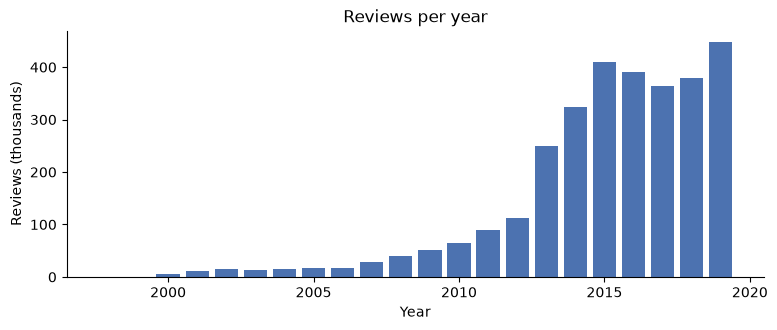

date,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,...,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
reviews,6,458,4825,10832,14349,14130,15269,16678,16467,28768,...,64491,90309,112097,249524,323573,410413,390297,364174,379551,447400


In [19]:
year_counts = df['date'].dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(year_counts.index, year_counts.values / 1e3, color='#4C72B0')
ax.set_xlabel('Year')
ax.set_ylabel('Reviews (thousands)')
ax.set_title('Reviews per year')
plt.show()
year_counts.to_frame('reviews').T

In [20]:
sample_text = audit_sample['text'].fillna('')
sample_title = audit_sample['title'].fillna('')
non_ascii_share = sample_text.str.count(r'[^\x00-\x7f]') / sample_text.str.len().clip(lower=1)
common_words = r'\b(?:the|and|is|it|to|of|this|you|for|with|but|was|not|are|have|game)\b'

pd.Series({
    'text contains HTML tags such as <br />': sample_text.str.contains(r'<[^>]+>', regex=True).mean(),
    'text contains a URL': sample_text.str.contains(r'https?://|www\.', regex=True).mean(),
    'text with more than 30% non-ASCII characters': (non_ascii_share > 0.3).mean(),
    'text without any common English word': (~sample_text.str.contains(common_words, case=False, regex=True)).mean(),
    'text shorter than 3 characters': (sample_text.str.strip().str.len() < 3).mean(),
    'title shorter than 3 characters': (sample_title.str.strip().str.len() < 3).mean(),
}).to_frame('share of audit_sample').style.format('{:.2%}')

,share of audit_sample
text contains HTML tags such as,16.03%
text contains a URL,0.08%
text with more than 30% non-ASCII characters,0.10%
text without any common English word,12.74%
text shorter than 3 characters,0.37%
title shorter than 3 characters,0.40%


The English check is a rough estimate. A review with no common English word is either written in another language or very short, so the number is an upper bound for non-English text.

**Findings for 3.4.**

- All values respect the dataset's own rules: no rating outside 1 to 5, no fractional rating, no negative vote count, no timestamp before 1996, and no timestamp on or after the cutoff.
- The data starts in 1998 and ends on 31 December 2019. Volume grows over time: 84.3% of the reviews were written from 2013 to 2019, and every year before 2007 has under 30,000 reviews.
- In the 500,000 review sample, 16.03% of texts contain HTML tags, and 0.08% contain a URL.
- 12.74% of texts contain no common English word. This mixes non-English reviews with very short reviews, so it is an upper bound for non-English text. Only 0.10% of texts are mostly non-ASCII.
- Very short text (under 3 characters) is rare: 0.37% of texts and 0.40% of titles.

### 3.5 Outliers

An outlier is a value far from the rest of its column. This check only finds them. Section 4 decides what to do. The standard 1.5 x IQR rule is applied to the review length and to `helpful_vote`, and then tested for whether it can be trusted on each column.

In [21]:
lengths = pd.DataFrame({
    'title_chars': df['title'].fillna('').str.len(),
    'text_chars': df['text'].fillna('').str.len(),
})
quantiles = [0.01, 0.25, 0.5, 0.75, 0.9, 0.99, 0.999]
summary = pd.concat([
    lengths.quantile(quantiles).T,
    df[['helpful_vote']].quantile(quantiles).T,
])
summary['max'] = [lengths['title_chars'].max(), lengths['text_chars'].max(), df['helpful_vote'].max()]
summary

,0.01,0.25,0.5,0.75,0.9,0.99,0.999,max
title_chars,3.0,10.0,16.0,31.0,49.0,88.0,126.000,605
text_chars,4.0,45.0,131.0,328.0,796.0,3490.0,8435.938,36893
helpful_vote,0.0,0.0,0.0,1.0,3.0,21.0,119.000,10369


In [22]:
rows = []
for name, s in [('title_chars', lengths['title_chars']), ('text_chars', lengths['text_chars']),
                ('helpful_vote', df['helpful_vote'])]:
    q1, q3 = s.quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    rows.append({'column': name, 'q1': q1, 'q3': q3, 'upper_fence': upper,
                 'above_fence': (s > upper).sum(), 'above_fence_pct': (s > upper).mean() * 100,
                 'zero_pct': (s == 0).mean() * 100})
pd.DataFrame(rows).set_index('column')

,q1,q3,upper_fence,above_fence,above_fence_pct,zero_pct
column,,,,,,
title_chars,10.0,31.0,62.5,131376,4.315855,0.000000
text_chars,45.0,328.0,752.5,325141,10.681261,0.010611
helpful_vote,0.0,1.0,2.5,308417,10.131858,71.352108


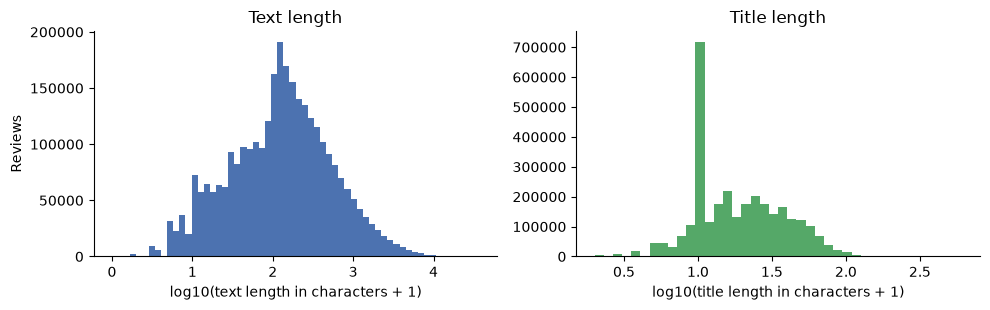

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(np.log10(lengths['text_chars'] + 1), bins=60, color='#4C72B0')
axes[0].set_xlabel('log10(text length in characters + 1)')
axes[0].set_ylabel('Reviews')
axes[0].set_title('Text length')
axes[1].hist(np.log10(lengths['title_chars'] + 1), bins=40, color='#55A868')
axes[1].set_xlabel('log10(title length in characters + 1)')
axes[1].set_title('Title length')
plt.tight_layout()
plt.show()

**Findings for 3.5.**

- Text length is right-skewed on a log scale: median 131 characters, 75th percentile 328, 99th percentile 3,490 and a maximum of 36,893.
- Titles are short: median 16 characters, 99th percentile 88 and a maximum of 605. The title histogram has a sharp spike at about 10 characters. That is the length of default titles such as "Five Stars", which is examined in 3.7.
- The 1.5 x IQR rule flags 10.68% of texts (above 752.5 characters), 4.32% of titles (above 62.5) and 10.13% of `helpful_vote` values (above 2.5). Such a high share means the rule is not suited to these skewed columns. The flagged long reviews are real reviews, not errors.
- `helpful_vote` is 0 for 71.35% of reviews, so its quartiles are almost meaningless, and it is not used as a feature anyway.
- Extreme lengths are kept. TF-IDF features are length normalised, so a long review does not dominate the model.

### 3.6 Target Distribution

How is the outcome distributed, and what does that mean for evaluation? First the raw star ratings, then the binary target after rating 3 is set aside.

In [24]:
rating_table = df['rating'].value_counts().sort_index().to_frame('reviews')
rating_table['share'] = (rating_table['reviews'] / len(df)).round(4)
rating_table

,reviews,share
rating,,
1.0,338794,0.1113
2.0,155379,0.0510
3.0,230235,0.0756
4.0,447171,0.1469
5.0,1872453,0.6151


In [25]:
binary = label.dropna().map({0.0: 'negative (1 to 2 stars)', 1.0: 'positive (4 to 5 stars)'}).value_counts()
binary_table = binary.to_frame('reviews')
binary_table['share'] = (binary_table['reviews'] / binary_table['reviews'].sum()).round(4)
print(binary_table)
print(f"\nImbalance ratio (positive per negative): {binary.iloc[0] / binary.iloc[1]:.2f}")
print(f"Accuracy of always answering positive   : {binary_table['share'].max():.2%}")

                         reviews   share
rating                                  
positive (4 to 5 stars)  2319624  0.8244
negative (1 to 2 stars)   494173  0.1756

Imbalance ratio (positive per negative): 4.69
Accuracy of always answering positive   : 82.44%


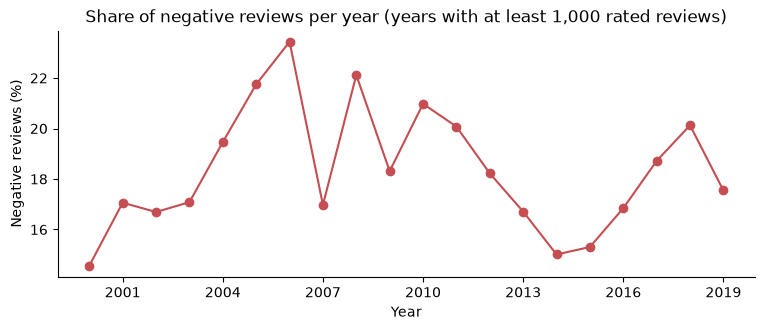

year,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,...,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
reviews,5,419,4257,9612,12802,12592,13586,14732,14486,25365,...,57310,80772,101946,228417,297986,381395,362422,338738,354563,421794
negative_share,0.0,0.1695,0.1456,0.1706,0.1669,0.1708,0.1946,0.2175,0.2344,0.1698,...,0.2098,0.2008,0.1822,0.1671,0.1501,0.1531,0.1684,0.1872,0.2013,0.1755


In [26]:
by_year = pd.DataFrame({'year': df['date'].dt.year, 'label': label}).dropna()
negative_share = by_year.groupby('year')['label'].agg(reviews='size', negative_share=lambda s: 1 - s.mean())
MIN_YEAR_REVIEWS = 1000
plot_data = negative_share[negative_share['reviews'] >= MIN_YEAR_REVIEWS]

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(plot_data.index, plot_data['negative_share'] * 100, marker='o', color='#C44E52')
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_xlabel('Year')
ax.set_ylabel('Negative reviews (%)')
ax.set_title(f'Share of negative reviews per year (years with at least {MIN_YEAR_REVIEWS:,} rated reviews)')
plt.show()
negative_share.round(4).astype(object).T

**Findings for 3.6.**

**Raw rating (five values)**
- 5 stars: 1,872,453 reviews (61.51%); 4 stars: 447,171 (14.69%); 3 stars: 230,235 (7.56%); 2 stars: 155,379 (5.10%); 1 star: 338,794 (11.13%).

**Binary target (rating 3 set aside)**
- 2,813,797 rated reviews remain: 2,319,624 positive (82.44%) and 494,173 negative (17.56%), about 4.69 positive reviews for every negative one.
- A model that always answers positive would reach 82.44% accuracy and still find no complaint. Macro-F1 is used for that reason, and the negative class needs attention (class weights and threshold choice).

**Over time**
- The negative share changes with the year, from about 15% (2014) to 23.4% (2006) among years with at least 1,000 rated reviews. It was 15.3% in 2015 and 17.6% in 2019.
- Because the mix changes over time, a time based split is the honest way to measure performance, and the results are checked by year in Section 9.

### 3.7 Possible Leakage

Leakage means the model gets information it would not have at prediction time, or information that reveals the answer. The model is meant to score a new review, so only the title and the text are allowed as inputs. These checks look at the structure of the data for risks.

- `rating` defines the label, so it can never be an input.
- `helpful_vote` is only known after other users have read the review, and `verified_purchase` is not part of the review text. Neither is used.
- The star rating may be written inside the title or the text. Many titles are the default star text, for example "Five Stars" or "One Star", which is the label in words.
- The same reviewer, the same product or the same text can appear on both sides of a split.

The overlap checks use a time based split on the rated reviews (oldest 70% for training, next 15% for validation, newest 15% for test). This is the split planned for the model and is only used here to measure overlap.

In [27]:
default_title = r'^\s*(?:[1-5](?:\.0)?\s*(?:out of 5\s*)?stars?|(?:one|two|three|four|five)\s*stars?)\s*[.!]*\s*$'
rating_in_text = r'\b(?:[0-5](?:\.\d)?\s*(?:/|out of)\s*(?:5|10)|[1-5]\s*(?:stars?|star rating)|(?:one|two|three|four|five)\s*stars?)\b'

sample_label = label.loc[audit_sample.index]
rated_mask = sample_label.notna()
class_name = sample_label.map({0.0: 'negative', 1.0: 'positive'})

checks = pd.DataFrame({
    'title is a default star title': audit_sample['title'].fillna('').str.contains(default_title, case=False, regex=True),
    'title mentions a rating': audit_sample['title'].fillna('').str.contains(rating_in_text, case=False, regex=True),
    'text mentions a rating': audit_sample['text'].fillna('').str.contains(rating_in_text, case=False, regex=True),
})[rated_mask]

by_class = checks.groupby(class_name[rated_mask]).mean()
by_class.insert(0, 'reviews', class_name[rated_mask].value_counts())
print(by_class.round(4).to_string())

default_rows = checks['title is a default star title']
print(f"\nReviews with a default star title            : {default_rows.sum():,} ({default_rows.mean():.2%} of rated reviews)")
print(f"Share of those that are positive             : {sample_label[rated_mask][default_rows].mean():.2%}")

          reviews  title is a default star title  title mentions a rating  text mentions a rating
rating                                                                                           
negative    80916                         0.1158                   0.1191                  0.0394
positive   381216                         0.2235                   0.2258                  0.0270

Reviews with a default star title            : 94,560 (20.46% of rated reviews)
Share of those that are positive             : 90.09%


In [28]:
rated = df.loc[~is_rated_3, ['timestamp', 'user_id', 'parent_asin']].copy()
rated['norm'] = pd.util.hash_pandas_object(norm_text[rated.index], index=False)
t70, t85 = rated['timestamp'].quantile([0.70, 0.85])

part = pd.Series('train', index=rated.index)
part[rated['timestamp'] > t70] = 'validation'
part[rated['timestamp'] > t85] = 'test'
earlier = {'validation': ['train'], 'test': ['train', 'validation']}

rows = []
for name, before in earlier.items():
    now = rated[part == name]
    past = rated[part.isin(before)]
    rows.append({
        'split': name,
        'reviews': len(now),
        'reviewer seen before': now['user_id'].isin(set(past['user_id'])).mean(),
        'product seen before': now['parent_asin'].isin(set(past['parent_asin'])).mean(),
        'text seen before': now['norm'].isin(set(past['norm'])).mean(),
    })
pd.DataFrame(rows).set_index('split').style.format({'reviews': '{:,.0f}', 'reviewer seen before': '{:.2%}',
                                                    'product seen before': '{:.2%}', 'text seen before': '{:.2%}'})

,reviews,reviewer seen before,product seen before,text seen before
split,,,,
validation,"422,069",23.27%,74.33%,14.80%
test,"422,070",22.08%,77.31%,15.77%


In [29]:
print('Split boundaries:', pd.to_datetime(t70, unit='ms').date(), 'and', pd.to_datetime(t85, unit='ms').date())
print(part.value_counts()[['train', 'validation', 'test']])
del rated, part

Split boundaries: 2017-10-19 and 2018-12-31
train         1969658
validation     422069
test           422070
Name: count, dtype: int64


**Findings for 3.7.**

**Default star titles**
- 20.46% of rated reviews (94,560 in the sample) have a title that is only the star rating in words, such as "Five Stars". That is 22.35% of positive reviews and 11.58% of negative reviews. Among these reviews, 90.09% are positive.
- Titles that mention a rating overall behave the same (22.58% of positive and 11.91% of negative reviews). In the text, a rating mention is much rarer (2.70% of positive and 3.94% of negative reviews).
- A default title restates the label, so a model could read the answer from the title alone and look better than it really is. The risk sits in the title, not in the text. This is handled in Section 4.

**Reviewers, products and texts across a time split (oldest 70% train, next 15% validation, newest 15% test)**
- Split boundaries: 2017-10-19 and 2018-12-31, giving 1,969,658 training, 422,069 validation and 422,070 test reviews.
- Reviewer seen before: 23.27% of validation and 22.08% of test reviews.
- Product seen before: 74.33% of validation and 77.31% of test reviews.
- Text seen before: 14.80% of validation and 15.77% of test reviews. These are mostly short generic phrases.
- Product overlap is natural and not harmful for a sentiment model, because the same product can receive new reviews. Repeated generic texts are a mild optimistic bias, so Section 9 also reports the score on reviews whose text was not seen in training.
- `rating`, `helpful_vote` and `verified_purchase` are excluded from the inputs.

### 3.8 Summary of Issues and Planned Treatment

The plan below is confirmed or adjusted in Section 4.

| # | Issue | Evidence | Planned treatment |
|---|---|---|---|
| 1 | Rating 3 is ambiguous | 230,235 reviews (7.56%) | Remove, as the assignment states |
| 2 | Blank review text | 325 reviews, all with a title | Remove |
| 3 | Exact duplicate rows | 35,056 rows (1.15%) | Remove, keeping the first occurrence |
| 4 | Repeated generic texts | 17.22% of rated reviews, 868 texts with both labels | Keep, since they are real opinions. Report the score on unseen texts in Section 9 |
| 5 | HTML tags in text | 16.03% of the sample | Replace tags with a space |
| 6 | URLs | 0.08% of the sample | Keep, no action needed |
| 7 | Non-English text | Up to 12.74% of the sample | Keep and Report the share |
| 8 | Default star titles that restate the label | 20.46% of rated reviews, 90.09% of them positive | Mask the title in these cases and test the effect on the score |
| 9 | Long reviews flagged by the IQR rule | 10.68% of texts above 752.5 characters | Keep, no capping |
| 10 | Strong class imbalance | 82.44% positive, 17.56% negative | Macro-F1, class weights and a threshold chosen on validation data |
| 11 | Negative share changes over time | About 15% to 23% across years | Time based split and results by year |
| 12 | Reviewer, product and text overlap across a time split | 22% to 23% of reviewers, 74% to 77% of products and 15% to 16% of texts seen before | Accept for reviewers and products. Report the unseen text score |
| 13 | Fields not allowed as inputs | `rating`, `helpful_vote`, `verified_purchase` | Excluded from the features |

## 4. Data Preparation

This section turns the audit of Section 3 into cleaned data. Every step is a fixed rule (a known label definition, a documented placeholder, a logical exclusion). Nothing is learned from the data, so it is safe to do before the train, validation and test split. Anything that learns from the data (vocabulary, weights, thresholds) comes later and is fitted on the training part only.

The steps follow the plan from Section 3.8:

1. Set aside rating 3 and create the label.
2. Remove reviews with blank text.
3. Remove exact duplicate rows.
4. Clean the text (HTML entities, HTML tags, extra whitespace).
5. Handle default star titles.
6. Decide what to do with outliers, non-English text and repeated texts.
7. Assemble the clean data frame `df_clean`.

A log records how many reviews each step removes. First, the objects created for the audit are released to free memory. The raw data frame `df` stays available until the end of this section.

In [30]:
audit_objects = ['audit_sample', 'norm_text', 'lengths', 'per_user', 'per_product', 'exact_dup',
                 'same_user_product', 'title_blank', 'text_blank', 'eligible', 'dup_text', 'dup_idx',
                 'checks', 'by_class', 'default_rows', 'class_name', 'rated_mask', 'sample_label',
                 'sample_text', 'sample_title', 'non_ascii_share', 'by_year', 'plot_data']
for name in audit_objects:
    globals().pop(name, None)
gc.collect()

prep_log = [('raw reviews before the cutoff', len(df))]

### 4.1 Label and Rating 3

Ratings 1 and 2 are negative (label 0) and ratings 4 and 5 are positive (label 1). Rating 3 is neutral and ambiguous, so the assignment drops it.

In [31]:
work = df.loc[df['rating'] != 3].copy()
work['label'] = (work['rating'] >= 4).astype('int8')
prep_log.append(('after removing rating 3', len(work)))
work['label'].value_counts().rename({1: 'positive', 0: 'negative'}).to_frame('reviews')

,reviews
label,
positive,2319624
negative,494173


### 4.2 Blank Text

A review without text has only a title left. The title alone is a weak input and often the default star title, so these reviews are removed.

In [32]:
work = work.loc[~blank(work['text'])]
prep_log.append(('after removing blank text', len(work)))
len(work)

2813487

### 4.3 Exact Duplicates

Rows that are identical in every stored column are the same review recorded twice. The first occurrence is kept.

In [33]:
work = work.drop_duplicates(subset=FIELDS, keep='first')
prep_log.append(('after removing exact duplicate rows', len(work)))
len(work)

2781136

### 4.4 Text Cleaning

The audit found HTML tags in about 16% of the texts. The rules for `title` and `text` are:

1. Decode HTML entities such as `&amp;` and `&quot;`.
2. Replace HTML tags (for example `<br />`) with a space. Only real tag shapes are matched, so text such as "I <3 this" is not touched.
3. Collapse repeated whitespace and trim the ends.

The case of the letters, punctuation, digits and non-English characters are kept as they are. Reviews whose text becomes empty after cleaning are removed.

In [34]:
TAG = r'</?[a-zA-Z][^>]*>'
ENTITY = r'&(?:#\d+|#x[0-9a-fA-F]+|[a-zA-Z]+);'

def clean_text(s):
    entity = s.str.contains(ENTITY, regex=True)
    s = s.copy()
    s.loc[entity] = s.loc[entity].map(html.unescape)
    tag = s.str.contains(TAG, regex=True)
    s = s.str.replace(TAG, ' ', regex=True).str.replace(r'\s+', ' ', regex=True).str.strip()
    return s, int(entity.sum()), int(tag.sum())

work['text'], text_entities, text_tags = clean_text(work['text'])
work['title'], title_entities, title_tags = clean_text(work['title'])

empty_after = work['text'] == ''
work = work.loc[~empty_after]
prep_log.append(('after removing text that is empty after cleaning', len(work)))

pd.DataFrame({'text': [text_entities, text_tags], 'title': [title_entities, title_tags]},
             index=['reviews with HTML entities', 'reviews with HTML tags'])

,text,title
reviews with HTML entities,77362,1347
reviews with HTML tags,423782,31


### 4.5 Default Star Titles

Section 3.7 found that many titles are only the star rating in words, such as "Five Stars". Such a title restates the label. Before deciding what to do, the next cell extracts the number of stars written in the title and compares it with the real rating.

In [35]:
DEFAULT_TITLE = r'^\s*(?:([1-5])(?:\.0)?\s*(?:out of 5\s*)?stars?|(one|two|three|four|five)\s*stars?)\s*[.!]*\s*$'
WORDS = {'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5}

extracted = work['title'].str.extract(DEFAULT_TITLE, flags=re.IGNORECASE)
title_stars = extracted[0].astype('float').fillna(extracted[1].str.lower().map(WORDS))
is_default = title_stars.notna()

print(f'Default star titles: {is_default.sum():,} ({is_default.mean():.2%} of reviews)')
print(f'Stars in the title equal the real rating in {(title_stars[is_default] == work.loc[is_default, "rating"]).mean():.2%} of them\n')
pd.crosstab(title_stars[is_default].astype(int).rename('stars in title'),
            work.loc[is_default, 'rating'].astype(int).rename('real rating'))

Default star titles: 571,949 (20.57% of reviews)
Stars in the title equal the real rating in 99.83% of them



real rating,1,2,4,5
stars in title,,,,
1,41256,29,77,137
2,72,15125,30,40
3,42,30,49,60
4,24,24,65157,118
5,129,39,71,449440


**Decision.** A default title is a copy of the rating, not something the reviewer wrote. A model that sees it learns to read the title instead of the review. So in these cases the title is replaced by an empty string and the cleaned title before masking is kept in `title_raw`. The flag `default_title` marks the affected reviews. Section 9 measures how much the score changes with and without the masking, so the effect is on record.

In [36]:
work['title_raw'] = work['title']
work['default_title'] = is_default
work.loc[is_default, 'title'] = ''
prep_log.append(('after masking default star titles (no rows removed)', len(work)))
work.loc[is_default, ['rating', 'title_raw', 'title']].head()

,rating,title_raw,title
22,1.0,One Star,
23,1.0,One Star,
24,5.0,Five Stars,
25,5.0,Five Stars,
26,5.0,Five Stars,


### 4.6 Outliers, Non-English Text and Repeated Texts

**Decision: these are kept.**

| Item | Treatment | Reason |
|---|---|---|
| Very long reviews | Kept, no capping | They are real reviews, not errors. TF-IDF features are length normalised, and a cap would have to be chosen from the data. |
| Very short reviews | Kept | Short reviews such as "good" and "great" are common and carry a clear opinion. |
| Non-English text | Kept | The assignment does not ask for a filter. The share is reported and the score is checked on it in Section 9. |
| Repeated generic texts | Kept | They are real opinions. Section 9 also reports the score on reviews whose text was not seen in training. |
| `helpful_vote`, `verified_purchase` | Kept in the data frame for analysis only | They are never model inputs. |

### 4.7 Clean Data Frame

The columns needed later are kept, and the reviews are sorted by time (oldest first), which the time based split relies on. The product variant `asin` is dropped because `parent_asin` already identifies the product.

In [37]:
df_clean = (work[['timestamp', 'date', 'rating', 'label', 'title', 'title_raw', 'default_title',
                  'text', 'helpful_vote', 'verified_purchase', 'user_id', 'parent_asin']]
            .sort_values('timestamp', kind='stable')
            .reset_index(drop=True))

assert not (df_clean['rating'] == 3).any()
assert set(df_clean['label'].unique()) == {0, 1}
assert not blank(df_clean['text']).any()
assert df_clean['timestamp'].is_monotonic_increasing
assert df_clean['date'].max() < CUTOFF
print('all checks passed')

all checks passed


In [38]:
flow = pd.DataFrame(prep_log, columns=['step', 'reviews'])
flow['removed'] = -flow['reviews'].diff().fillna(0).astype(int)
flow

,step,reviews,removed
0,raw reviews before the cutoff,3044032,0
1,after removing rating 3,2813797,230235
2,after removing blank text,2813487,310
3,after removing exact duplicate rows,2781136,32351
4,after removing text that is empty after cleaning,2781136,0
5,after masking default star titles (no rows removed),2781136,0


In [39]:
pd.Series({
    'reviews': f'{len(df_clean):,}',
    'columns': df_clean.shape[1],
    'share of raw reviews kept': f'{len(df_clean) / prep_log[0][1]:.2%}',
    'positive share': f"{df_clean['label'].mean():.2%}",
    'negative share': f"{1 - df_clean['label'].mean():.2%}",
    'reviews with a masked default title': f"{df_clean['default_title'].sum():,}",
    'earliest review': str(df_clean['date'].min().date()),
    'latest review': str(df_clean['date'].max().date()),
    'memory used': f"{df_clean.memory_usage(deep=True).sum() / 1e9:.2f} GB",
}).to_frame('df_clean')

,df_clean
reviews,"2,781,136"
columns,12
share of raw reviews kept,91.36%
positive share,82.45%
negative share,17.55%
reviews with a masked default title,"571,949"
earliest review,1998-11-17
latest review,2019-12-31
memory used,1.31 GB


In [40]:
df_clean.head()

,timestamp,date,rating,label,title,title_raw,default_title,text,helpful_vote,verified_purchase,user_id,parent_asin
0,911332729000,1998-11-17 19:58:49+00:00,5.0,1,Epic,Epic,False,I was first inspired by Paddle to the Sea as a young lad in kindergarden. To this day paddle fos...,7,False,AF7R3EAZILCCEAF3A3PMGHDHJT3A,6304202377
1,913518485000,1998-12-13 03:08:05+00:00,5.0,1,Fantastic sountrack,Fantastic sountrack,False,I have listened to this soundtrack almost everyday going to and from work for about one year. It...,1,False,AH7JHWVL4IO3QLJQAKPIHDXKZPKA,B00000DFE7
2,913605858000,1998-12-14 03:24:18+00:00,5.0,1,UFO w/Michael Schenker is back & better than ever!,UFO w/Michael Schenker is back & better than ever!,False,"Who would have thought that Michael Schenker would ever get back together with UFO? Well, he has...",1,False,AHTOO3G5QYDXGBJJAW42TZINE57A,B0000061R7
3,913939847000,1998-12-18 00:10:47+00:00,4.0,1,Annual must see for Peanuts fans.,Annual must see for Peanuts fans.,False,"Yes, it's campy. Yes, it has sub-standard animation. But, you can't beat the feeling you get whe...",0,False,AFEWSVDMDSQUYOGBQMQXSGXW5SRQ,6303154751
4,914130615000,1998-12-20 05:10:15+00:00,5.0,1,THE DREAM TEAM,THE DREAM TEAM,False,"The album opens with a destructive guitar chord in a song with a melodic bridge and chorus, and ...",9,False,AFL7YEZT2BCDZLOV4V3JHVXK2N3A,B0000061R7


The raw data frame and the working copy are no longer needed, so they are released. All later sections use `df_clean`. To inspect the raw data again, re-run the loading cell of Section 2.4.

In [41]:
del df, work, extracted, title_stars, is_default, empty_after
gc.collect()

0

**Findings for Section 4.**

**Rating 3 and blank text**
- Rating 3 removed 230,235 reviews (7.56% of the raw data). The 2,813,797 rated reviews that remain are 2,319,624 positive and 494,173 negative.
- 310 reviews with blank text were removed. The audit counted 325, but 15 of them were already gone with rating 3.

**Duplicates**
- 32,351 exact duplicate rows were removed (1.15% of the remaining reviews). The audit counted 35,056 over all ratings, and the rest were rating 3 rows.

**Text cleaning**
- Text: 423,782 reviews (15.24% of the final data) contained HTML tags and 77,362 contained HTML entities. Titles were affected much less: 31 had tags and 1,347 had entities.
- No review became empty after cleaning, so this step removed nothing.
- The first rows of `df_clean` show the entities decoded, for example "&" in a title that was written as `&amp;`.

**Default star titles**
- 571,949 reviews (20.57%) have a title that is only a star rating, such as "Five Stars".
- In 99.83% of them (570,978) the stars in the title equal the real rating, so the title restates the label. 971 reviews disagree, for example a title with 5 stars on a review rated 1. 181 of those have "3 stars" in the title, which cannot match any kept rating.
- 56,770 of these titles belong to negative reviews and 515,179 to positive reviews, so the default title is common in both classes and would be an easy shortcut for a model.
- All of them are masked. The cleaned title before masking is kept in `title_raw`, and `default_title` flags the reviews.

**Result**
- The clean data `df_clean` has 2,781,136 reviews (91.36% of the raw data) and 12 columns. It is 82.45% positive and 17.55% negative, almost the same as before cleaning, so the cleaning did not change the balance.
- It covers 1998-11-17 to 2019-12-31, is sorted by time, and uses 1.31 GB of memory. All checks passed: no rating 3, labels only 0 and 1, no blank text, time order and the cutoff respected.

### 4.8 Summary of Data Preparation

| Step | Rule | Result |
|---|---|---|
| Label | Rating 1 and 2 are negative (0), rating 4 and 5 are positive (1) | 2,319,624 positive and 494,173 negative before duplicates |
| Rating 3 | Removed | 230,235 reviews |
| Blank text | Removed | 310 reviews |
| Exact duplicates | Removed, first occurrence kept | 32,351 rows |
| HTML entities and tags | Decoded and replaced by a space, whitespace collapsed | 77,362 and 423,782 texts changed, nothing removed |
| Default star titles | Title masked, original kept in `title_raw`, flag in `default_title` | 571,949 reviews masked (20.57%) |
| Outliers, non-English text, repeated texts | Kept | See the decision table in 4.6 |
| Final data | `df_clean`, sorted by time | 2,781,136 reviews, 82.45% positive, 17.55% negative |

The next section explores `df_clean`. It describes the data only, and nothing from it is fitted or stored.

## 5. Exploratory Data Analysis

This section looks at `df_clean` to see how each variable is distributed and how it relates to the label (negative 17.55%, positive 82.45% overall). It is descriptive: nothing is fitted or stored for the models, and it only informs the decisions of Section 6.

**Only the oldest 70% of the reviews are used here.** Anything that looks at the label can influence design choices, so the validation and test periods stay unseen. The oldest 70% of `df_clean` (it is sorted by time) will be the training set, and Section 7 uses the same boundary. The numbers below therefore describe the training period, and the later years are only examined in Section 9.

The words in a review are counted by splitting on whitespace. Negative reviews use the colour red and positive reviews use blue in the charts.

In [42]:
TRAIN_FRACTION = 0.70
n_train = int(len(df_clean) * TRAIN_FRACTION)
eda = df_clean.iloc[:n_train]
NEG, POS = '#C44E52', '#4C72B0'

num = pd.DataFrame({
    'label': eda['label'],
    'words': eda['text'].str.count(r'\S+'),
    'title_words': eda['title'].str.count(r'\S+'),
    'helpful_vote': eda['helpful_vote'],
    'verified': eda['verified_purchase'],
    'default_title': eda['default_title'],
    'year': eda['date'].dt.year,
})
print(f"Reviews used: {len(eda):,} ({eda['date'].min().date()} to {eda['date'].max().date()})")

Reviews used: 1,946,795 (1998-11-17 to 2017-10-20)


### 5.1 Univariate Analysis

How is each variable distributed on its own?

In [43]:
class_table = eda['label'].value_counts().rename({1: 'positive', 0: 'negative'}).to_frame('reviews')
class_table['share'] = (class_table['reviews'] / len(eda)).round(4)
class_table

,reviews,share
label,,
positive,1616769,0.8305
negative,330026,0.1695


In [44]:
num[['words', 'title_words', 'helpful_vote']].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).T.style.format('{:,.1f}')

,count,mean,std,min,25%,50%,75%,90%,99%,max
words,"1,946,795.0",69.5,142.1,1.0,9.0,27.0,69.0,164.0,672.0,"5,928.0"
title_words,"1,946,795.0",3.8,3.9,0.0,1.0,3.0,6.0,9.0,17.0,59.0
helpful_vote,"1,946,795.0",1.6,17.5,0.0,0.0,0.0,1.0,3.0,22.0,"10,369.0"


In [45]:
pd.Series({
    'verified purchase': num['verified'].mean(),
    'default star title (masked)': num['default_title'].mean(),
    'title blank in the original data': (eda['title_raw'] == '').mean(),
    'at least one helpful vote': (num['helpful_vote'] > 0).mean(),
    'text with 5 words or fewer': (num['words'] <= 5).mean(),
}).to_frame('share').round(4)

,share
verified purchase,0.7944
default star title (masked),0.2431
title blank in the original data,0.0000
at least one helpful vote,0.3131
text with 5 words or fewer,0.1764


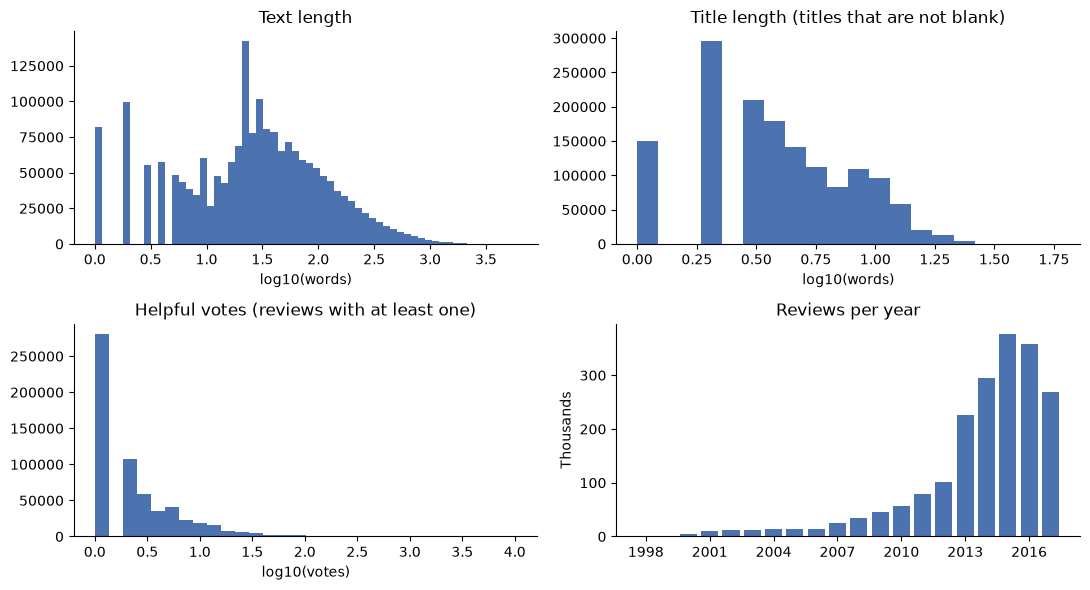

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
axes[0, 0].hist(np.log10(num['words']), bins=60, color=POS)
axes[0, 0].set_title('Text length')
axes[0, 0].set_xlabel('log10(words)')
axes[0, 1].hist(np.log10(num.loc[num['title_words'] > 0, 'title_words']), bins=20, color=POS)
axes[0, 1].set_title('Title length (titles that are not blank)')
axes[0, 1].set_xlabel('log10(words)')
axes[1, 0].hist(np.log10(num.loc[num['helpful_vote'] > 0, 'helpful_vote']), bins=30, color=POS)
axes[1, 0].set_title('Helpful votes (reviews with at least one)')
axes[1, 0].set_xlabel('log10(votes)')
year_counts = num['year'].value_counts().sort_index()
axes[1, 1].bar(year_counts.index, year_counts.values / 1e3, color=POS)
axes[1, 1].set_title('Reviews per year')
axes[1, 1].set_ylabel('Thousands')
axes[1, 1].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

**Findings for 5.1.**

**Data used**
- The oldest 70% of `df_clean`: 1,946,795 reviews from 1998-11-17 to 2017-10-20.
- 1,616,769 are positive (83.05%) and 330,026 are negative (16.95%), close to the 82.45% and 17.55% of the full data.

**Text and title**
- The text is short and right-skewed: median 27 words, mean 69.5, 90th percentile 164, 99th percentile 672 and a maximum of 5,928. 17.64% of the texts have 5 words or fewer.
- Titles have a median of 3 words (99th percentile 17, maximum 59). Masked default titles count as 0 words. The spikes at 1 and 2 words in the histograms come from very common short phrases.

**Other variables**
- `helpful_vote` is 0 for 68.69% of the reviews (mean 1.6, maximum 10,369).
- 79.44% of the reviews are verified purchases, and 24.31% have a masked default star title.
- No title was blank in the original data.

**Over time**
- Reviews per year grow from under 15,000 until 2006 to a peak of 376,888 in 2015. The years 2013 to 2017 hold 78.3% of the training reviews, and 2017 is only partly covered (up to 20 October).

### 5.2 Length, Votes and Other Variables vs the Label

Do negative and positive reviews look different on the variables that are not words? Group summaries and rank correlations first, then the share of negative reviews across value ranges.

In [47]:
by_label = num.groupby('label').agg(
    reviews=('label', 'size'),
    median_words=('words', 'median'),
    mean_words=('words', 'mean'),
    median_title_words=('title_words', 'median'),
    share_with_votes=('helpful_vote', lambda s: (s > 0).mean()),
    mean_votes=('helpful_vote', 'mean'),
    verified_share=('verified', 'mean'),
    default_title_share=('default_title', 'mean'),
).rename(index={0: 'negative', 1: 'positive'})
by_label.T.style.format('{:,.3f}')

label,negative,positive
reviews,"330,026.000","1,616,769.000"
median_words,43.000,25.000
mean_words,87.160,65.885
median_title_words,4.000,3.000
share_with_votes,0.524,0.270
mean_votes,3.129,1.280
verified_share,0.690,0.816
default_title_share,0.135,0.265


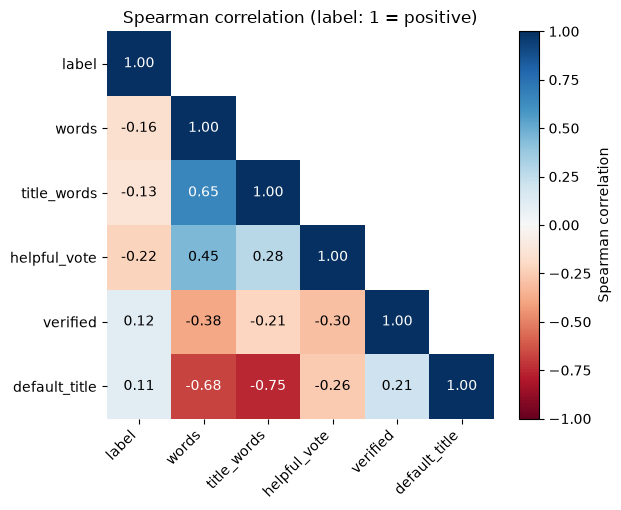

In [48]:
corr_cols = ['label', 'words', 'title_words', 'helpful_vote', 'verified', 'default_title']
corr = num[corr_cols].astype('int64').corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
shown_corr = corr.mask(mask)

fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(shown_corr, cmap='RdBu', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha='right')
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(i + 1):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center',
                color='white' if abs(corr.iloc[i, j]) > 0.6 else 'black')
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, label='Spearman correlation')
ax.set_title('Spearman correlation (label: 1 = positive)')
plt.tight_layout()
plt.show()

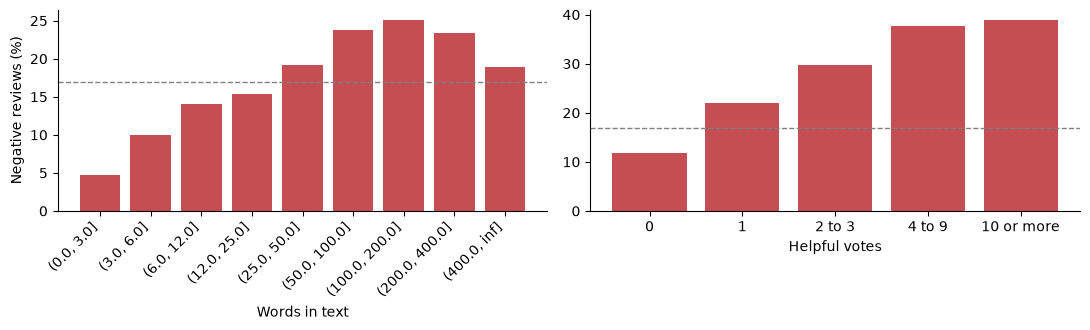

,reviews,negative_share
words,,
"(0.0, 3.0]",237444,0.0468
"(3.0, 6.0]",149179,0.0995
"(6.0, 12.0]",184841,0.1400
"(12.0, 25.0]",362194,0.1538
"(25.0, 50.0]",385891,0.1914
"(50.0, 100.0]",288645,0.2372
"(100.0, 200.0]",188419,0.2515
"(200.0, 400.0]",97138,0.2335
"(400.0, inf]",53044,0.1896


In [49]:
len_bins = pd.cut(num['words'], [0, 3, 6, 12, 25, 50, 100, 200, 400, np.inf])
neg_by_len = (1 - num['label']).groupby(len_bins, observed=True).agg(['size', 'mean'])
neg_by_len.columns = ['reviews', 'negative_share']

vote_bins = pd.cut(num['helpful_vote'], [-1, 0, 1, 3, 9, np.inf], labels=['0', '1', '2 to 3', '4 to 9', '10 or more'])
neg_by_vote = (1 - num['label']).groupby(vote_bins, observed=True).agg(['size', 'mean'])
neg_by_vote.columns = ['reviews', 'negative_share']

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(range(len(neg_by_len)), neg_by_len['negative_share'] * 100, color=NEG)
axes[0].set_xticks(range(len(neg_by_len)), [str(i) for i in neg_by_len.index], rotation=45, ha='right')
axes[0].set_xlabel('Words in text')
axes[0].set_ylabel('Negative reviews (%)')
axes[0].axhline(100 * (1 - num['label'].mean()), color='grey', linestyle='--', linewidth=1)
axes[1].bar(range(len(neg_by_vote)), neg_by_vote['negative_share'] * 100, color=NEG)
axes[1].set_xticks(range(len(neg_by_vote)), list(neg_by_vote.index))
axes[1].set_xlabel('Helpful votes')
axes[1].axhline(100 * (1 - num['label'].mean()), color='grey', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()
neg_by_len.round(4)

In [50]:
neg_by_vote.round(4)

,reviews,negative_share
helpful_vote,,
0,1337288,0.1174
1,280820,0.2195
2 to 3,165574,0.2974
4 to 9,107676,0.3763
10 or more,55437,0.3899


In [51]:
rate = (1 - num['label']).groupby(
    [num['verified'].map({True: 'verified', False: 'not verified'}),
     num['default_title'].map({True: 'default title', False: 'other title'})]
).agg(['size', 'mean'])
rate.columns = ['reviews', 'negative_share']
rate.round(4)

reviews  negative_share
verified     default_title                         
not verified default title    26400          0.1605
             other title     373774          0.2627
verified     default title   446920          0.0905
             other title    1099701          0.1702

**Findings for 5.2.**

**Group differences (negative against positive reviews)**
- Negative reviews are longer: median 43 words against 25 (mean 87.2 against 65.9), and their titles are slightly longer (4 words against 3).
- They get more helpful votes: 52.4% have at least one vote against 27.0%, and the mean is 3.13 votes against 1.28.
- They are less often verified purchases (69.0% against 81.6%) and less often have a default title (13.5% against 26.5%).

**Correlations (Spearman, heatmap)**
- Every variable is only weakly related to the label: `helpful_vote` -0.22, `words` -0.16, `title_words` -0.13, `verified` 0.12 and `default_title` 0.11. None of them separates the classes alone.
- The predictors are related to each other: `words` and `title_words` 0.65, `words` and `helpful_vote` 0.45, `verified` and `words` -0.38.
- `default_title` has -0.68 with `words` and -0.75 with `title_words`. The second value is partly built in, because a masked title has 0 words.

**Length**
- The share of negative reviews rises with length and then falls: 4.68% for 3 words or fewer, 15.38% for 12 to 25 words, 25.15% for 100 to 200 words and 18.96% above 400 words.
- Very short reviews are almost all positive (generic praise such as "great" and "good").

**Helpful votes**
- The share of negative reviews climbs from 11.74% with no votes to 21.95% with 1 vote, 29.74% with 2 to 3, 37.63% with 4 to 9 and 38.99% with 10 or more.
- Votes only arrive after a review has been read by others, so they cannot be used as a feature, however strong the link is.

**Verified purchase and default title**
- Negative shares by group: verified with default title 9.05%, verified with another title 17.02%, not verified with default title 16.05% and not verified with another title 26.27%.
- Both flags go with fewer negative reviews, which is another reason to mask the default titles and not give the flags to the model.

### 5.3 Words vs the Label

Which words and word pairs separate negative from positive reviews? A random sample of 200,000 reviews is used. For each term, the share of reviews that contain it is compared between the classes with a smoothed log odds ratio (positive means more typical of positive reviews, negative means more typical of negative reviews). Only terms that appear in at least 150 reviews are shown. Titles are examined separately, without the masked default titles.

In [52]:
def term_table(texts, y, min_df):
    vec = CountVectorizer(ngram_range=(1, 2), min_df=min_df, binary=True, dtype=np.int32)
    X = vec.fit_transform(texts)
    pos = np.asarray(X[(y == 1).values].sum(axis=0)).ravel()
    neg = np.asarray(X[(y == 0).values].sum(axis=0)).ravel()
    n_pos, n_neg = (y == 1).sum(), (y == 0).sum()
    log_odds = np.log((pos + 1) / (n_pos + 2)) - np.log((neg + 1) / (n_neg + 2))
    return pd.DataFrame({'term': vec.get_feature_names_out(), 'in_positive': pos,
                         'in_negative': neg, 'log_odds': log_odds}).set_index('term')

sample = eda.sample(200_000, random_state=SEED)
text_terms = term_table(sample['text'], sample['label'], min_df=150)
print(f'{len(text_terms):,} terms kept')
pd.concat({'most positive': text_terms.nlargest(15, 'log_odds'),
           'most negative': text_terms.nsmallest(15, 'log_odds')}).round(3)

13,632 terms kept


in_positive  in_negative  log_odds
              term                                                 
most positive excelente                  555            1     4.035
              not disappoint             271            0     4.013
              grandson loved             195            0     3.685
              excellent product          559            2     3.636
              super fun                  350            1     3.575
              definitely worth           783            4     3.462
              enjoys playing             154            0     3.450
              great gift                 305            1     3.438
              loves it                  3594           24     3.375
              totally worth              286            1     3.373
              loves them                 258            1     3.271
              great buy                  759            5     3.249
              must for                   242            1     3.207
              great value                452            3     3.137
              only downside              438            3     3.105
most negative for refund                  13          208    -4.296
              very disappointed           66          680    -3.912
              waste your                  77          690    -3.774
              money back                  40          360    -3.768
              don waste                   64          532    -3.697
              refund                     109          849    -3.638
              waste of                   156         1183    -3.613
              poor quality                19          141    -3.553
              worst game                  23          164    -3.521
              even work                   26          182    -3.507
              never buy                   34          215    -3.413
              unacceptable                28          177    -3.407
              uninstalled                 23          144    -3.392
              return this                 25          145    -3.318
              not buy                    193         1070    -3.301

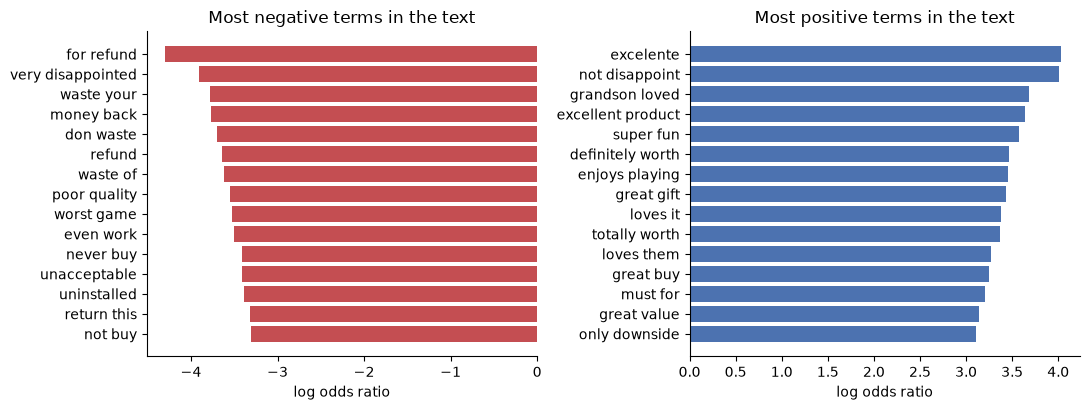

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
top_neg = text_terms.nsmallest(15, 'log_odds').iloc[::-1]
top_pos = text_terms.nlargest(15, 'log_odds').iloc[::-1]
axes[0].barh(top_neg.index, top_neg['log_odds'], color=NEG)
axes[0].set_title('Most negative terms in the text')
axes[1].barh(top_pos.index, top_pos['log_odds'], color=POS)
axes[1].set_title('Most positive terms in the text')
for ax in axes:
    ax.set_xlabel('log odds ratio')
plt.tight_layout()
plt.show()

In [54]:
title_sample = sample.loc[(sample['title'] != '')]
title_terms = term_table(title_sample['title'], title_sample['label'], min_df=50)
print(f"{len(title_sample):,} titles used, {len(title_terms):,} terms kept")
pd.concat({'most positive': title_terms.nlargest(12, 'log_odds'),
           'most negative': title_terms.nsmallest(12, 'log_odds')}).round(3)

151,263 titles used, 2,500 terms kept


in_positive  in_negative  log_odds
              term                                                 
most positive loves it                   625            1     4.313
              rocks                      264            0     4.147
              have for                   263            0     4.143
              great gift                 246            0     4.076
              works perfectly            227            0     3.996
              fast shipping              185            0     3.793
              loves                     1060            5     3.742
              great fun                  342            1     3.712
              kids love                  326            1     3.664
              family fun                 153            0     3.604
              awesome game               874            5     3.549
              fun fun                    144            0     3.544
most negative waste of                     4          422    -5.871
              waste your                   4          340    -5.656
              worthless                    0           58    -5.511
              dont waste                   0           55    -5.458
              garbage                      5          307    -5.371
              of crap                      0           50    -5.365
              unplayable                   1           93    -5.283
              very disappointed            3          167    -5.171
              worst game                   2          108    -5.026
              waste                       23          841    -4.991
              junk                         8          270    -4.838
              buyer beware                 3          114    -4.792

In [55]:
shared = title_terms.index.intersection(text_terms.index)
pd.Series({
    'terms in the text list': len(text_terms),
    'terms in the title list': len(title_terms),
    'terms in both': len(shared),
    'correlation of log odds, text vs title (shared terms)': np.corrcoef(text_terms.loc[shared, 'log_odds'],
                                                                         title_terms.loc[shared, 'log_odds'])[0, 1],
}, dtype=object).to_frame('value')

,value
terms in the text list,13632
terms in the title list,2500
terms in both,2457
"correlation of log odds, text vs title (shared terms)",0.896745


**Findings for 5.3.**

**Words in the text (200,000 reviews, 13,632 terms in at least 150 reviews)**
- The most positive terms express enjoyment, value and gifts: "loves it" (3,594 positive reviews against 24 negative), "excellent product", "definitely worth", "great gift", "super fun" and "not disappoint".
- The most negative terms are about refunds, wasted money and broken products: "refund" (849 negative against 109 positive), "waste of" (1,183 against 156), "very disappointed", "money back", "never buy", "worst game" and "uninstalled".
- The Spanish word "excelente" is one of the strongest positive terms (555 positive reviews against 1 negative). Non-English text therefore carries signal and should be kept.

**Words in the title (151,263 of the 200,000 sampled reviews have a title that is not masked; 2,500 terms in at least 50 titles)**
- The same kind of words appear, with stronger log odds: "waste of" (-5.87), "worthless" (0 positive against 58 negative), "garbage" (5 against 307), "unplayable", "loves it" (625 against 1) and "rocks" (264 against 0).
- 2,457 of the 2,500 title terms also appear in the text list, and the log odds of the two lists agree closely (correlation 0.90). A word carries the same sentiment in the title and in the text, and the title is a short, sharp summary of the review.

**Reading the numbers**
- These log odds describe the training sample. They show which wording matters, and the models in Section 8 learn the weights themselves.

### 5.4 Multivariate Analysis and Change over Time

Is the picture stable across the years of the training period, and do the signals behave differently across groups, for example short against long reviews for verified and unverified purchases?

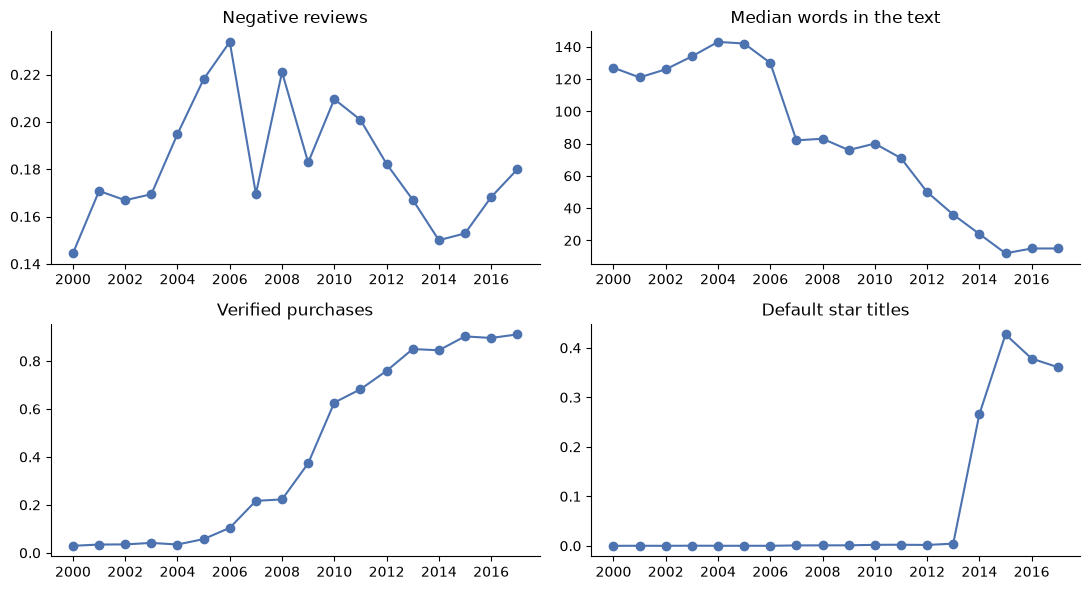

,reviews,negative_share,median_words,verified_share,default_title_share
year,,,,,
1998,5,0.0000,55.0,0.0000,0.0000
1999,408,0.1667,97.5,0.0368,0.0000
2000,4202,0.1445,127.0,0.0293,0.0000
2001,9520,0.1708,121.0,0.0346,0.0001
2002,12637,0.1669,126.0,0.0352,0.0000
2003,12413,0.1694,134.0,0.0414,0.0002
2004,13420,0.1949,143.0,0.0347,0.0001
2005,14522,0.2180,142.0,0.0574,0.0001
2006,14334,0.2338,130.0,0.1042,0.0001


In [56]:
yearly = num.groupby('year').agg(
    reviews=('label', 'size'),
    negative_share=('label', lambda s: 1 - s.mean()),
    median_words=('words', 'median'),
    verified_share=('verified', 'mean'),
    default_title_share=('default_title', 'mean'),
)
shown = yearly[yearly['reviews'] >= 1000]

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, col, title in [(axes[0, 0], 'negative_share', 'Negative reviews'),
                       (axes[0, 1], 'median_words', 'Median words in the text'),
                       (axes[1, 0], 'verified_share', 'Verified purchases'),
                       (axes[1, 1], 'default_title_share', 'Default star titles')]:
    ax.plot(shown.index, shown[col], marker='o', color=POS)
    ax.set_title(title)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()
yearly.round(4)

In [57]:
neg_len_ver = (1 - num['label']).groupby(
    [len_bins, num['verified'].map({True: 'verified', False: 'not verified'})], observed=True
).mean().unstack().round(4)
neg_len_ver

verified,not verified,verified
words,,
"(0.0, 3.0]",0.0969,0.0441
"(3.0, 6.0]",0.1723,0.0951
"(6.0, 12.0]",0.2194,0.1340
"(12.0, 25.0]",0.2290,0.1449
"(25.0, 50.0]",0.2738,0.1748
"(50.0, 100.0]",0.2945,0.2133
"(100.0, 200.0]",0.2859,0.2232
"(200.0, 400.0]",0.2476,0.2139
"(400.0, inf]",0.1923,0.1836


In [58]:
len_ver_share = num.groupby([len_bins, num['verified'].map({True: 'verified', False: 'not verified'})], observed=True).size().unstack()
(len_ver_share / len_ver_share.sum()).round(4)

verified,not verified,verified
words,,
"(0.0, 3.0]",0.0311,0.1455
"(3.0, 6.0]",0.0211,0.0910
"(6.0, 12.0]",0.0324,0.1111
"(12.0, 25.0]",0.0961,0.2093
"(25.0, 50.0]",0.1619,0.2076
"(50.0, 100.0]",0.2126,0.1316
"(100.0, 200.0]",0.2122,0.0669
"(200.0, 400.0]",0.1413,0.0262
"(400.0, inf]",0.0913,0.0107


**Findings for 5.4.**

**The data changes a lot over the years**
- Reviews became much shorter: the median is 121 to 143 words from 2000 to 2005, 82 in 2007, 36 in 2013, 24 in 2014 and 12 to 15 words from 2015 to 2017.
- Verified purchases grow from about 3% (2000 to 2005) to 21.7% in 2007, 62.7% in 2010 and 91.1% in 2017.
- Default star titles are almost absent before 2013 (below 0.5%), then reach 26.6% in 2014, 42.7% in 2015, 37.8% in 2016 and 36.1% in 2017.
- The share of negative reviews moves between 14.5% and 23.4% from year to year (15.0% in 2014 and 18.0% in 2017) and shows no steady trend.
- The training period therefore holds two very different kinds of reviews, long and unverified older reviews and short, verified recent ones. The validation and test periods (from October 2017) look like the recent kind.

**Length and verified purchase together**
- Not verified reviews are more negative in every length group, for example 29.45% against 21.33% for 50 to 100 words and 9.69% against 4.41% for 3 words or fewer.
- Both groups show the same pattern with length (rising, then falling), so the length effect is not caused by the verified flag.
- Not verified reviews are much longer: only 3.11% have 3 words or fewer and 9.13% have more than 400 words, against 14.55% and 1.07% for verified reviews. This matches the change of the platform over time.

### 5.5 Summary of EDA

EDA found a few clear signals, several weak ones, and a strong change over time. Nothing is fitted here. The decisions are taken in Section 6.

| What EDA showed | What it means for Section 6 and later |
|---|---|
| The classes are imbalanced: 83.05% positive and 16.95% negative in the training period | Macro-F1 as the metric, class weights and a threshold chosen on validation data |
| Words carry most of the signal: refund, waste, disappointed, loves it, great gift. Some terms are not English ("excelente") | TF-IDF features. Test the n-gram range (unigrams only, up to bigrams, up to trigrams). Keep non-English text. Test character n-grams for other languages and spelling variants |
| The title is a short and sharp summary of the review and uses the same words as the text (log odds correlation 0.90) | Compare the title and text joined into one input against separate TF-IDF blocks for the title and the text |
| 24.31% of the reviews have a default star title, almost all since 2014 | Keep the masking from Section 4. Measure the score with and without it in Section 9 |
| Length is only weakly related to the label (Spearman -0.16) and not in a straight line | TF-IDF is length normalised, so test a few simple length features as optional extras |
| `helpful_vote` (-0.22) and `verified` (0.12) relate to the label but are not review content, and votes only exist after publication | Exclude both from the features |
| The predictors are correlated with each other (for example `words` and `title_words` 0.65) | No action for linear models with regularisation |
| Reviews became shorter, more often verified and more often carry default titles over the years | Time based split, results by year in Section 9, and a check in Section 8 of whether recent reviews alone or recency weights help |

## 6. Feature Engineering

This section decides how a review is turned into model input. Each candidate is tested with a short experiment and the best supported choice is kept. The questions are:

- Should the title be joined with the text, kept separate, or left out? Does masking the default star title matter?
- Which word n-grams are useful: unigrams only, up to bigrams, or up to trigrams?
- Do character n-grams add something to words?
- Which TF-IDF settings work well (frequency cutoffs, sublinear term frequency, stop words, case)?
- Do simple length and style features help?

**How the experiments are run.** They use only the oldest 70% of the reviews, the training period of Section 5, so the validation and test periods stay untouched. Inside that period:

- the **fit part** is a random sample of 150,000 reviews from the first 85% of the period,
- the **dev part** is a random sample of 75,000 reviews from the last 15%, the most recent reviews of the period, which look most like the validation and test periods.

Every candidate is scored with the same simple classifier (a linear SVM with balanced class weights) so that only the features change. The score is macro-F1 on the dev part at the default decision threshold. The final model, its tuning and the threshold come in Sections 7 to 9.

**How differences are read.** The dev part is a sample, so small differences can be luck. The spread of macro-F1 is estimated with a bootstrap, and a difference smaller than twice that spread is treated as a tie. Among ties, the simpler and cheaper setup is kept. Anything that learns from the data (vocabulary, scaling) is fitted on the fit part only.

In [59]:
FE_FIT_SIZE, FE_DEV_SIZE = 150_000, 75_000
split_at = int(len(eda) * 0.85)
fe_fit = eda.iloc[:split_at].sample(FE_FIT_SIZE, random_state=SEED)
fe_dev = eda.iloc[split_at:].sample(FE_DEV_SIZE, random_state=SEED)
y_fit, y_dev = fe_fit['label'].to_numpy(), fe_dev['label'].to_numpy()

pd.DataFrame({
    'reviews': [len(fe_fit), len(fe_dev)],
    'from': [fe_fit['date'].min().date(), fe_dev['date'].min().date()],
    'to': [fe_fit['date'].max().date(), fe_dev['date'].max().date()],
    'positive share': [y_fit.mean().round(4), y_dev.mean().round(4)],
}, index=['fit part', 'dev part'])

,reviews,from,to,positive share
fit part,150000,1999-11-09,2016-12-16,0.8327
dev part,75000,2016-12-16,2017-10-20,0.8201


In [60]:
results = []

def join_title(frame, masked=True):
    title = frame['title'] if masked else frame['title_raw']
    return title + ' . ' + frame['text']

def tfidf(**kw):
    params = dict(ngram_range=(1, 2), min_df=5, sublinear_tf=True, strip_accents='unicode', dtype=np.float32)
    params.update(kw)
    return TfidfVectorizer(**params)

def fit_eval(group, name, X_fit, X_dev, vec_seconds):
    t0 = time.time()
    clf = LinearSVC(C=0.5, class_weight='balanced', random_state=SEED).fit(X_fit, y_fit)
    fit_seconds = time.time() - t0
    pred = clf.predict(X_dev)
    f1_neg, f1_pos = f1_score(y_dev, pred, average=None)
    results.append({'group': group, 'name': name, 'features': X_fit.shape[1],
                    'vectorise_s': round(vec_seconds), 'fit_s': round(fit_seconds),
                    'f1_negative': f1_neg, 'f1_positive': f1_pos, 'macro_f1': (f1_neg + f1_pos) / 2})
    return pred

def run_tfidf(group, name, fit_text, dev_text, **kw):
    t0 = time.time()
    vec = tfidf(**kw)
    X_fit = vec.fit_transform(fit_text)
    X_dev = vec.transform(dev_text)
    pred = fit_eval(group, name, X_fit, X_dev, time.time() - t0)
    return X_fit, X_dev, pred

def show(group):
    rows = [r for r in results if r['group'] == group or r['name'] == REFERENCE_NAME]
    table = pd.DataFrame(rows).drop(columns='group').set_index('name')
    table['vs_reference'] = table['macro_f1'] - REFERENCE_F1
    return table.style.format({'f1_negative': '{:.4f}', 'f1_positive': '{:.4f}', 'macro_f1': '{:.4f}',
                               'vs_reference': '{:+.4f}', 'features': '{:,.0f}'})

### 6.1 Title and Text as Input

How should the title enter the model? Four candidates are compared on word unigrams and bigrams (minimum 5 reviews per term, sublinear term frequency):

- **Reference:** the title (default star titles masked) and the text joined into one string.
- **Text only:** the title is left out.
- **Unmasked title:** the title and text are joined, but the default star titles are not masked. This shows how much the default titles help a model, which is the shortcut that the masking in Section 4 removes.
- **Separate blocks:** the title and the text get their own TF-IDF vocabulary, and the two blocks are placed side by side.

In [61]:
fit_in, dev_in = join_title(fe_fit), join_title(fe_dev)
REFERENCE_NAME = 'reference: title and text joined'
X_ref_fit, X_ref_dev, ref_pred = run_tfidf('input', REFERENCE_NAME, fit_in, dev_in)
REFERENCE_F1 = results[-1]['macro_f1']

def bootstrap_std(y, pred, n=200):
    scores = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        scores.append(f1_score(y[idx], pred[idx], average='macro'))
    return float(np.std(scores))

NOISE = bootstrap_std(y_dev, ref_pred)
print(f'reference macro-F1 = {REFERENCE_F1:.4f}, bootstrap spread = {NOISE:.4f}, tie threshold = {2 * NOISE:.4f}')

reference macro-F1 = 0.9254, bootstrap spread = 0.0012, tie threshold = 0.0024


In [62]:
_ = run_tfidf('input', 'text only (no title)', fe_fit['text'], fe_dev['text'])
_ = run_tfidf('input', 'unmasked default titles', join_title(fe_fit, masked=False), join_title(fe_dev, masked=False))

t0 = time.time()
title_vec, text_vec = tfidf(), tfidf()
sep_fit = sparse.hstack([title_vec.fit_transform(fe_fit['title']), text_vec.fit_transform(fe_fit['text'])]).tocsr()
sep_dev = sparse.hstack([title_vec.transform(fe_dev['title']), text_vec.transform(fe_dev['text'])]).tocsr()
_ = fit_eval('input', 'separate title and text blocks', sep_fit, sep_dev, time.time() - t0)
del sep_fit, sep_dev
show('input')

,features,vectorise_s,fit_s,f1_negative,f1_positive,macro_f1,vs_reference
name,,,,,,,
reference: title and text joined,"237,491",19,4,0.8786,0.9723,0.9254,+0.0000
text only (no title),"229,796",18,5,0.8597,0.9678,0.9137,-0.0117
unmasked default titles,"237,862",19,4,0.9085,0.9793,0.9439,+0.0184
separate title and text blocks,"246,035",19,5,0.8777,0.9725,0.9251,-0.0004


### 6.2 Word N-gram Range

Do word pairs and word triples add anything beyond single words? Triples such as "waste of money" or "would not recommend" can capture negation and fixed phrases, but they make the vocabulary much larger and sparser. Three ranges are compared on the reference input, with the same minimum of 5 reviews per term. The number of features and the time are reported next to the score.

In [63]:
_ = run_tfidf('ngram', 'unigrams only', fit_in, dev_in, ngram_range=(1, 1))
_ = run_tfidf('ngram', 'up to trigrams', fit_in, dev_in, ngram_range=(1, 3))
show('ngram')

,features,vectorise_s,fit_s,f1_negative,f1_positive,macro_f1,vs_reference
name,,,,,,,
reference: title and text joined,"237,491",19,4,0.8786,0.9723,0.9254,+0.0000
unigrams only,"25,120",6,5,0.8307,0.9584,0.8945,-0.0309
up to trigrams,"469,071",40,6,0.8823,0.9734,0.9279,+0.0024


### 6.3 Character N-grams

Character n-grams look inside words, so they can cope with spelling mistakes, word endings and languages that the word vocabulary covers poorly. They produce many more features. `CHAR_MAX_CHARS` limits how many characters of each review are used. It is set to `None`, so the full reviews are used and no text is cut off.

**Warning: `CHAR_MAX_CHARS = None` needs a lot of memory (roughly 6 to 8 GB extra) and can fail with an out-of-memory error on a small machine. If the kernel crashes or the cell is killed, set it to a number such as `600` (this keeps about 80% to 85% of the reviews complete). Close other programs before running this cell.**

Two candidates are compared with the reference: character n-grams alone (3 to 5 characters inside word boundaries, at most 500,000 features) and words together with characters.

In [64]:
CHAR_MAX_CHARS = None

t0 = time.time()
char_vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=5, max_features=500_000,
                           sublinear_tf=True, dtype=np.float32)
C_fit = char_vec.fit_transform(fit_in.str[:CHAR_MAX_CHARS])
C_dev = char_vec.transform(dev_in.str[:CHAR_MAX_CHARS])
char_seconds = time.time() - t0

_ = fit_eval('char', 'character n-grams only', C_fit, C_dev, char_seconds)
_ = fit_eval('char', 'words plus character n-grams', sparse.hstack([X_ref_fit, C_fit]).tocsr(),
             sparse.hstack([X_ref_dev, C_dev]).tocsr(), char_seconds)
del C_fit, C_dev
show('char')

,features,vectorise_s,fit_s,f1_negative,f1_positive,macro_f1,vs_reference
name,,,,,,,
reference: title and text joined,"237,491",19,4,0.8786,0.9723,0.9254,+0.0000
character n-grams only,"171,904",67,14,0.8387,0.9606,0.8996,-0.0258
words plus character n-grams,"409,395",67,20,0.8785,0.9723,0.9254,-0.0000


**Findings for 6.3.**

- Character n-grams alone are clearly worse than the reference: macro-F1 0.8996 against 0.9254 (-0.0258), far outside the tie threshold of 0.0024.
- Words together with characters score 0.9254, the same as the reference (difference -0.0000), so the characters add no signal on top of the words.
- The cost is large: 409,395 features instead of 237,491, vectorising takes 73 seconds instead of 17, and fitting takes 17 seconds instead of 4.

**Decision: character n-grams are not used.** They tie with the reference at about four times the vectorising time and 72% more features. The reference stays word n-grams on the joined title and text.

### 6.4 Vectoriser Settings

Which TF-IDF settings work best? Each candidate changes one setting of the reference:

- sublinear term frequency off (raw counts instead of 1 plus the log of the count),
- minimum number of reviews per term of 2 and of 20 (reference: 5),
- at most 100,000 features,
- English stop words removed (this also removes words like "not", which matter for negation),
- case kept instead of lower-casing.

In [65]:
_ = run_tfidf('settings', 'sublinear tf off', fit_in, dev_in, sublinear_tf=False)
_ = run_tfidf('settings', 'min_df 2', fit_in, dev_in, min_df=2)
_ = run_tfidf('settings', 'min_df 20', fit_in, dev_in, min_df=20)
_ = run_tfidf('settings', 'at most 100,000 features', fit_in, dev_in, max_features=100_000)
_ = run_tfidf('settings', 'English stop words removed', fit_in, dev_in, stop_words='english')
_ = run_tfidf('settings', 'case kept', fit_in, dev_in, lowercase=False)
show('settings')

,features,vectorise_s,fit_s,f1_negative,f1_positive,macro_f1,vs_reference
name,,,,,,,
reference: title and text joined,"237,491",19,4,0.8786,0.9723,0.9254,+0.0000
sublinear tf off,"237,491",20,5,0.8775,0.9720,0.9247,-0.0007
min_df 2,"622,698",21,6,0.8801,0.9728,0.9265,+0.0010
min_df 20,"69,159",18,6,0.8728,0.9707,0.9217,-0.0037
"at most 100,000 features","100,000",24,6,0.8754,0.9714,0.9234,-0.0020
English stop words removed,"158,299",14,3,0.8332,0.9613,0.8972,-0.0282
case kept,"251,469",20,5,0.8761,0.9718,0.9239,-0.0015


### 6.5 Length and Style Features

EDA showed that length is only weakly related to the label, and TF-IDF vectors are length normalised, so the length of a review is lost. A few simple numbers are tested as an addition to the reference: the log of the number of words, the log of the title length, and the amount of exclamation marks, question marks and capital letters. They are scaled with a scaler fitted on the fit part. They are also tested alone to see how much signal they carry by themselves.

In [66]:
def style_features(frame):
    text = frame['text']
    return pd.DataFrame({
        'log_words': np.log1p(text.str.count(r'\S+')),
        'log_title_words': np.log1p(frame['title'].str.count(r'\S+')),
        'exclamations': np.log1p(text.str.count('!')),
        'questions': np.log1p(text.str.count(r'\?')),
        'capital_share': text.str.count(r'[A-Z]') / text.str.len().clip(lower=1),
    })

scaler = StandardScaler(with_mean=False)
S_fit = sparse.csr_matrix(scaler.fit_transform(style_features(fe_fit)).astype(np.float32))
S_dev = sparse.csr_matrix(scaler.transform(style_features(fe_dev)).astype(np.float32))

_ = fit_eval('style', 'style features only', S_fit, S_dev, 0)
_ = fit_eval('style', 'reference plus style features', sparse.hstack([X_ref_fit, S_fit]).tocsr(),
             sparse.hstack([X_ref_dev, S_dev]).tocsr(), 0)
show('style')

/home/virtuozs/college/MLOps/Tugas1/project/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,features,vectorise_s,fit_s,f1_negative,f1_positive,macro_f1,vs_reference
name,,,,,,,
reference: title and text joined,"237,491",19,4,0.8786,0.9723,0.9254,+0.0000
style features only,5,0,0,0.3618,0.7754,0.5686,-0.3569
reference plus style features,"237,496",0,59,0.8788,0.9724,0.9256,+0.0002


### 6.6 All Experiments Together

All candidates ranked by macro-F1. The shaded band marks twice the bootstrap spread around the reference, so a bar inside the band is a tie with the reference.

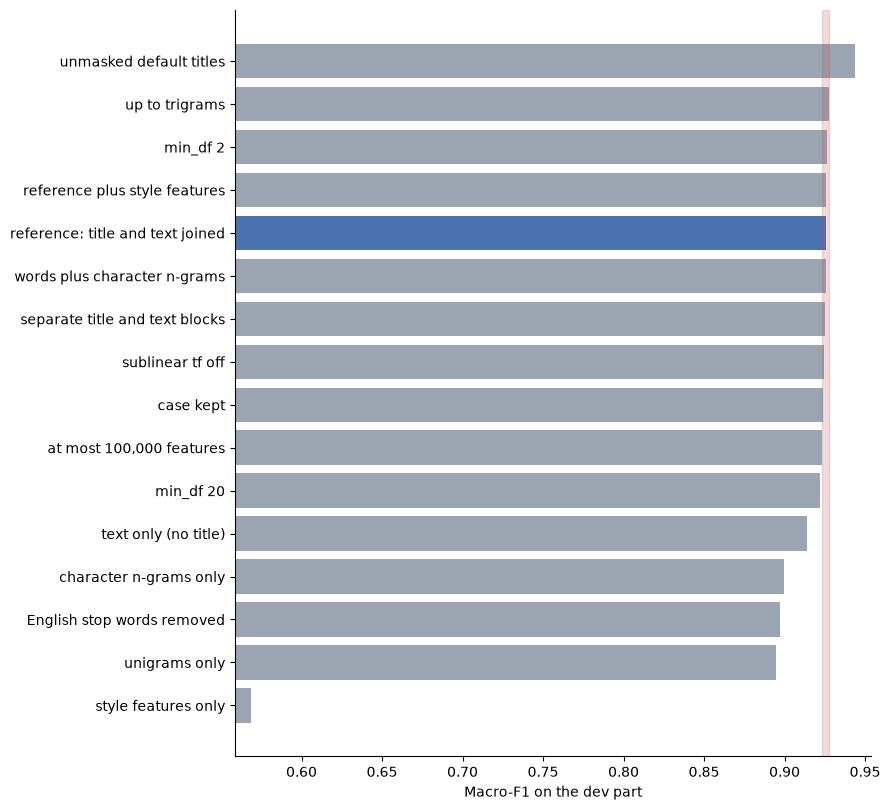

,features,vectorise_s,fit_s,f1_negative,f1_positive,macro_f1
name,,,,,,
unmasked default titles,237862,19,4,0.9085,0.9793,0.9439
up to trigrams,469071,40,6,0.8823,0.9734,0.9279
min_df 2,622698,21,6,0.8801,0.9728,0.9265
reference plus style features,237496,0,59,0.8788,0.9724,0.9256
reference: title and text joined,237491,19,4,0.8786,0.9723,0.9254
words plus character n-grams,409395,67,20,0.8785,0.9723,0.9254
separate title and text blocks,246035,19,5,0.8777,0.9725,0.9251
sublinear tf off,237491,20,5,0.8775,0.9720,0.9247
case kept,251469,20,5,0.8761,0.9718,0.9239


In [67]:
all_results = pd.DataFrame(results).drop_duplicates('name').sort_values('macro_f1')

fig, ax = plt.subplots(figsize=(9, 0.45 * len(all_results) + 1))
ax.barh(all_results['name'], all_results['macro_f1'], color=[POS if n == REFERENCE_NAME else '#9AA5B1' for n in all_results['name']])
ax.axvspan(REFERENCE_F1 - 2 * NOISE, REFERENCE_F1 + 2 * NOISE, color=NEG, alpha=0.2)
ax.set_xlim(all_results['macro_f1'].min() - 0.01, all_results['macro_f1'].max() + 0.01)
ax.set_xlabel('Macro-F1 on the dev part')
plt.tight_layout()
plt.show()

all_results.sort_values('macro_f1', ascending=False).drop(columns='group').set_index('name').round(4)

### 6.7 Summary of Feature Engineering

Tie threshold: 0.0024 macro-F1 (twice the bootstrap spread). A difference inside it is not treated as real.

| Question | Result | Decision for the next section |
|---|---|---|
| Title and text | Joined input scores 0.9254. Text only drops to 0.9137 (-0.0117). Separate blocks tie (-0.0004) | Join the title and the text into one string |
| Default titles | Unmasked titles score 0.9439, but that is the rating copied into the input | Keep them masked. Do not use this score as a target |
| Word n-grams | Unigrams only drops to 0.8945 (-0.0309). Up to trigrams gains +0.0024, at the threshold, with 469,071 features and 39 seconds against 17 | Use unigrams and bigrams. Trigrams can be rechecked on the validation set |
| Character n-grams | Alone 0.8996 (-0.0258). With words a tie (-0.0000) at 73 seconds and 409,395 features | Not used |
| Vectoriser settings | Sublinear off, min_df 2 and case kept are ties or slightly worse. min_df 20 (-0.0037), 100,000 features (-0.0020) and stop words (-0.0282) are worse | Keep the reference: min_df 5, sublinear tf, lower case, no stop words, no feature cap |
| Length and style features | Alone 0.5686. Added to the reference +0.0002, a tie, and the fit takes 61 seconds instead of 4 | Not used |

**Chosen input for Section 7:** one string made of the masked title and the text, vectorised with TF-IDF on word unigrams and bigrams (min_df 5, sublinear tf, accents removed, lower case, no stop words, no feature cap), about 237,000 features. Its macro-F1 on the dev part is 0.9254.

Nothing tested beats this reference by more than the noise, except trigrams which sit at its edge. The remaining gain has to come from the model and its settings, not from more features.

## 7. Baseline Model

Section 6 fixed how a review is turned into model input. This section sets up the data split and the validation scheme, builds the baselines that every later model has to beat, and records what the run cost. A score only means something next to a simple reference.

All models in this section are fitted on **all reviews of the training period** (1,946,795 reviews), with no sampling.

The questions are:

- What does this section cost to run, and what limits the results? This is stated first, because the fits are heavy.
- How are the reviews split, and what is scored where?
- How well does a model do that ignores the text, and one that counts a few obvious words?
- How well does a standard TF-IDF and logistic regression model do with default settings? This is the formal bar for the models after it.

### 7.1 Before You Run: Cost and Limitations

**This section is heavy.** Four baselines are scored in 7.3. Two of them, the TF-IDF models, are fitted on all 1,946,795 training reviews, with no sampling, and they make the section heavy. The majority class and the word counting rule need no fitting. On a 12 core machine with 34 GB of memory, building the features of the Section 6 baseline took about 4 minutes and fitting it about 2 minutes. The two TF-IDF fits together took about 7 minutes, and the notebook process held about 9 GB of memory afterwards (an earlier run peaked near 11 GB). Before running:

- use a machine with at least 16 GB of memory (the setup cell prints a warning below that) and close other heavy programs,
- expect a long wait in 7.3, because each fit runs in one cell without progress output,
- do not interrupt a fit. A stopped cell loses its result, although the data cached in `data/` is kept.

The cell below prints the machine of this run. Section 7.4 records the measured time and memory of the two TF-IDF fits.

**Limitations of this run**

- **One machine, CPU only.** Nothing here uses a GPU. The default logistic regression solver (`lbfgs`) works mostly on one core, so a machine with more cores would not make one fit much faster, and a machine with less memory could not hold the matrices of the fit on all reviews.
- **Memory is the hard limit.** The fit on all reviews builds a matrix with every training review as a row and over a million word and word pair columns. The step that counts word pairs before rare terms are dropped is the most demanding one. The table in 7.4 shows how close the run came to the memory of the machine.
- **Time limits how many fits are affordable.** One fit on all reviews takes minutes, so a long search with many models on all reviews takes hours.
- **Single run, single split.** There is one time based split and one fit per setting, so the bootstrap spread only measures the noise from the finite validation set. It does not measure the noise from training, such as a different random start of the solver.
- **Defaults on purpose.** The baselines use default settings and a solver capped at 1,000 iterations. No convergence warning was shown in this run. They are references, not tuned models.
- **The validation period is different from the training period.** Validation is more negative than training, so a score on it already includes some drift. The test set is newer again.

In [68]:
mem_total = psutil.virtual_memory().total / 1e9
print(f'machine: {os.cpu_count()} logical cores, {mem_total:.0f} GB memory, no GPU used (scikit-learn runs on the CPU)')
print(f'python {platform.python_version()}, scikit-learn {sklearn.__version__}')

machine: 12 logical cores, 34 GB memory, no GPU used (scikit-learn runs on the CPU)
python 3.11.15, scikit-learn 1.9.1


### 7.2 Split, Validation Scheme and Metric

The split is by time, because a deployed model scores new reviews that were written after the ones it learned from:

- **train:** the oldest 70% of the reviews (the training period of Sections 5 and 6),
- **validation:** the next 15%, used to compare models and to choose the decision threshold,
- **test:** the newest 15%, scored once at the end and never used for a choice.

Every model is fitted on the whole training period and scored on the whole validation set, so a score is neither a sample estimate nor a result of a lucky draw. Section 7.4 records how much time and memory the run needed.

The metric is macro-F1 at the default decision threshold of each model. The threshold is tuned later. Accuracy and the per-class scores are shown next to it.

In [69]:
VALID_FRACTION = 0.15
n_valid_end = int(len(df_clean) * (TRAIN_FRACTION + VALID_FRACTION))

train = df_clean.iloc[:n_train]
valid = df_clean.iloc[n_train:n_valid_end]
test = df_clean.iloc[n_valid_end:]
y_valid = valid['label'].to_numpy()

pd.DataFrame({
    'reviews': [len(f) for f in (train, valid, test)],
    'from': [f['date'].min().date() for f in (train, valid, test)],
    'to': [f['date'].max().date() for f in (train, valid, test)],
    'positive share': [train['label'].mean().round(4), y_valid.mean().round(4), 'held out'],
}, index=['train', 'validation', 'test'])

,reviews,from,to,positive share
train,1946795,1998-11-17,2017-10-20,0.8305
validation,417170,2017-10-20,2018-12-31,0.7968
test,417171,2018-12-31,2019-12-31,held out


**Findings for 7.2.**

- The training period has 1,946,795 reviews (November 1998 to 20 October 2017), validation has 417,170 (to 31 December 2018) and test has 417,171 (to 31 December 2019).
- Validation is more negative than training: 79.68% positive against 83.05%, so the negative share rises from 16.95% to 20.32%. The classes drift over time, and the validation score is the fairer guide to what the model will meet.

### 7.3 Baselines

Four references are scored on the validation set. The first two need no fitting on the text: the majority class only reads the training labels, and the word counting rule uses no training data. The last two are the TF-IDF models. They are the same pipeline with and without the Section 6 feature choices, so the gap between them shows what Section 6 bought.

| Baseline | Input | Method | What it shows |
|---|---|---|---|
| Majority class | none | always predicts the larger class (positive) | why accuracy is a poor metric here |
| Word counting rule | title and text | 20 positive and 20 negative words; negative when there are more negative than positive hits, positive on ties and when no word is found | what a hand written rule can do with no training |
| TF-IDF words and logistic regression, defaults | title and text joined; single words; plain `TfidfVectorizer` | `LogisticRegression` with default settings (`C=1`, no class weight), `max_iter=1000` so that the solver can finish | a plain text model |
| TF-IDF Section 6 features and logistic regression, defaults | title (default star titles masked) and text joined; words and word pairs, at least 5 reviews per term, sublinear term frequency, accents stripped, lower case, no stop words | the same logistic regression | **the formal baseline** |

The two TF-IDF baselines are fitted on the whole training period and scored on the whole validation set. The table also records the time and the memory in use, because the cost of a fit matters for what comes next.

In [70]:
def memory_gb():
    return psutil.Process().memory_info().rss / 1e9

y_train = train['label'].to_numpy()
baselines = []

def score_baseline(name, pred, vectorise_s=0, fit_s=0, features=0):
    p, r, f, _ = precision_recall_fscore_support(y_valid, pred, labels=[0, 1], zero_division=0)
    baselines.append({'name': name, 'accuracy': accuracy_score(y_valid, pred),
                      'precision_negative': p[0], 'recall_negative': r[0],
                      'f1_negative': f[0], 'f1_positive': f[1], 'macro_f1': f.mean(),
                      'features': features, 'vectorise_s': round(vectorise_s), 'fit_s': round(fit_s),
                      'memory_gb': round(memory_gb(), 1)})
    return pred

def fit_baseline(name, vec):
    t0 = time.time()
    X_fit = vec.fit_transform(join_title(train))
    X_valid = vec.transform(join_title(valid))
    vectorise_s = time.time() - t0
    t0 = time.time()
    clf = LogisticRegression(max_iter=1000).fit(X_fit, y_train)
    fit_s = time.time() - t0
    pred = score_baseline(name, clf.predict(X_valid), vectorise_s, fit_s, X_fit.shape[1])
    return vec, clf, X_fit, X_valid, pred

majority = int(pd.Series(y_train).mode()[0])
_ = score_baseline('majority class', np.full(len(y_valid), majority))

In [71]:
POSITIVE_WORDS = ['great', 'good', 'love', 'loved', 'loves', 'excellent', 'awesome', 'amazing', 'perfect', 'fun',
                  'best', 'enjoy', 'enjoyed', 'recommend', 'fantastic', 'beautiful', 'wonderful', 'favorite', 'happy', 'nice']
NEGATIVE_WORDS = ['bad', 'worst', 'terrible', 'awful', 'waste', 'refund', 'broken', 'disappointed', 'disappointing', 'boring',
                  'poor', 'useless', 'horrible', 'junk', 'defective', 'returned', 'unplayable', 'buggy', 'crashes', 'garbage']

counter = CountVectorizer(vocabulary=POSITIVE_WORDS + NEGATIVE_WORDS)
counts = counter.transform(join_title(valid))
pos_hits = np.asarray(counts[:, :len(POSITIVE_WORDS)].sum(axis=1)).ravel()
neg_hits = np.asarray(counts[:, len(POSITIVE_WORDS):].sum(axis=1)).ravel()
_ = score_baseline('word counting rule', (pos_hits >= neg_hits).astype(int))
print(f'reviews with at least one listed word: {((pos_hits + neg_hits) > 0).mean():.1%}')

reviews with at least one listed word: 74.5%


In [72]:
vec_plain, lr_plain, Xt_plain, Xv_plain, plain_pred = fit_baseline(
    'TF-IDF words + logistic regression (defaults)', TfidfVectorizer(dtype=np.float32))
del Xt_plain, Xv_plain
gc.collect()

9

In [73]:
BASELINE_NAME = 'TF-IDF Section 6 features + logistic regression (defaults)'
vec_base, lr_base, Xt, Xv, baseline_pred = fit_baseline(BASELINE_NAME, tfidf())

pd.DataFrame(baselines).set_index('name').style.format(
    {c: '{:.4f}' for c in ['accuracy', 'precision_negative', 'recall_negative', 'f1_negative', 'f1_positive', 'macro_f1']}
    | {'features': '{:,.0f}', 'memory_gb': '{:.1f}'})

,accuracy,precision_negative,recall_negative,f1_negative,f1_positive,macro_f1,features,vectorise_s,fit_s,memory_gb
name,,,,,,,,,,
majority class,0.7968,0.0000,0.0000,0.0000,0.8869,0.4435,0,0,0,5.5
word counting rule,0.8526,0.9092,0.3049,0.4567,0.9147,0.6857,0,0,0,5.6
TF-IDF words + logistic regression (defaults),0.9481,0.9067,0.8297,0.8665,0.9678,0.9171,"311,451",80,22,6.8
TF-IDF Section 6 features + logistic regression (defaults),0.9617,0.9352,0.8718,0.9024,0.9762,0.9393,"1,498,693",274,102,8.9


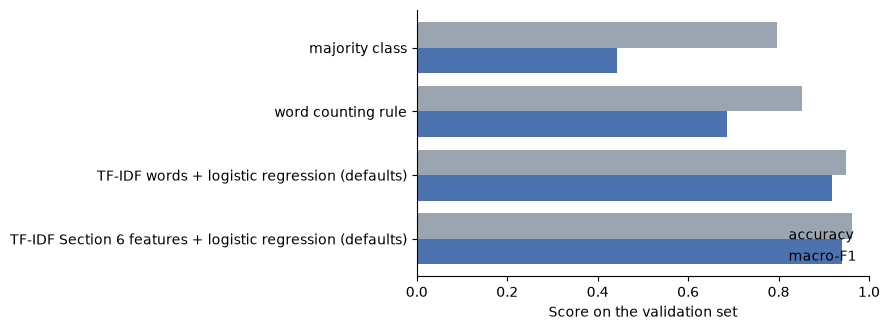

predicted,negative,positive
true,,
negative,73890,10862
positive,5121,327297


In [74]:
table = pd.DataFrame(baselines).set_index('name')
pos = np.arange(len(table))
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(pos - 0.2, table['accuracy'], 0.4, color='#9AA5B1', label='accuracy')
ax.barh(pos + 0.2, table['macro_f1'], 0.4, color=POS, label='macro-F1')
ax.set_yticks(pos, table.index)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel('Score on the validation set')
ax.legend(loc='lower right', frameon=False)
plt.tight_layout()
plt.show()

labels = {0: 'negative', 1: 'positive'}
pd.crosstab(pd.Series(y_valid, name='true').map(labels), pd.Series(baseline_pred, name='predicted').map(labels))

In [75]:
BASELINE_F1 = baselines[-1]['macro_f1']
VALID_NOISE = bootstrap_std(y_valid, baseline_pred)
print(f'baseline macro-F1 = {BASELINE_F1:.4f}, bootstrap spread = {VALID_NOISE:.4f}, tie threshold = {2 * VALID_NOISE:.4f}')

baseline macro-F1 = 0.9393, bootstrap spread = 0.0004, tie threshold = 0.0009


**Findings for 7.3.**

**Why accuracy misleads**
- The majority class rule reaches 79.68% accuracy and finds no negative review at all (recall 0). Its macro-F1 is only 0.4435.
- The word counting rule has 85.26% accuracy and a macro-F1 of 0.6857. When it says negative it is right 90.92% of the time, but it finds only 30.49% of the negative reviews. 74.5% of the reviews contain at least one listed word, and the rule answers positive on ties and on reviews without listed words, so it misses most complaints.

**The logistic regression baselines**
- TF-IDF on single words with default logistic regression scores 0.9171 macro-F1 (accuracy 94.81%).
- With the Section 6 features the same classifier scores 0.9393 (accuracy 96.17%), a gain of 0.0222. This is far above the tie threshold of 0.0009, so the Section 6 choices (word pairs, at least 5 reviews per term, sublinear term frequency, accent stripping) are worth keeping. This model is the formal baseline.
- The baseline is better at precision than at recall for the negative class: precision 0.9352 and recall 0.8718. Of 84,752 negative validation reviews it finds 73,890 and misses 10,862. It raises 5,121 false alarms among 332,418 positive reviews (1.54%).
- The default decision threshold and the missing class weights favour the larger class, so there is room to trade some precision for recall.
- The bootstrap spread on the validation set is 0.0004, so the tie threshold is 0.0009. Differences smaller than that are not treated as real.

### 7.4 Measured Cost of the Run

The table lists the time and memory of the two TF-IDF fits of Section 7.3, both on all 1,946,795 training reviews. The memory is the size of the whole notebook process while the matrices of that fit were still alive. It includes the data frames of earlier sections, so it is an upper bound for the fit alone and not a clean peak. The numbers depend on the machine printed in 7.1 and on what else was running.

In [76]:
tfidf_fits = [r for r in baselines if r['features'] > 0]
compute_rows = [{'step': r['name'], 'training reviews': len(train), 'features': r['features'],
                 'vectorise_s': r['vectorise_s'], 'fit_s': r['fit_s'], 'memory_gb': r['memory_gb']} for r in tfidf_fits]
compute_table = pd.DataFrame(compute_rows)
total_s = compute_table['vectorise_s'].sum() + compute_table['fit_s'].sum()
print(f'time in vectorising and fitting: {total_s:,.0f} s ({total_s / 60:.0f} min), largest memory in use: {compute_table["memory_gb"].max():.1f} GB')
compute_table.style.format({'training reviews': '{:,.0f}', 'features': '{:,.0f}', 'memory_gb': '{:.1f}'}).hide(axis='index')

time in vectorising and fitting: 478 s (8 min), largest memory in use: 8.9 GB


step,training reviews,features,vectorise_s,fit_s,memory_gb
TF-IDF words + logistic regression (defaults),"1,946,795","311,451",80,22,6.8
TF-IDF Section 6 features + logistic regression (defaults),"1,946,795","1,498,693",274,102,8.9


**Findings for 7.4.**

- Both TF-IDF baselines were fitted on all 1,946,795 training reviews. The plain model has 311,451 features and took 61 seconds to vectorise and 19 seconds to fit. The Section 6 model has 1,498,693 features and took 234 seconds to vectorise and 104 seconds to fit. Together this is 418 seconds (7 minutes) on 12 cores.
- Vectorising costs more than fitting, because counting word pairs is the demanding step. The memory in use grew from 5.6 GB before any fit to 6.8 GB and then 9.0 GB, so the run fits comfortably in 34 GB. No convergence warning was shown.

**Decision on training size**
- All fits use the whole training period. A check before this notebook was finalised, with the same model on a random sample of 300,000 training reviews, scored 0.9271 macro-F1 and a negative recall of 0.8331. That is 0.0122 below the score on all reviews, more than 13 times the tie threshold, so a sample would have understated the baseline. That check is not part of this notebook.
- The machine handles the full fit in about 6 minutes per model, so no sample is needed at this stage.

### 7.5 Summary of the Baseline

| Model | Accuracy | Negative recall | Macro-F1 | Role |
|---|---|---|---|---|
| Majority class | 0.7968 | 0.0000 | 0.4435 | Shows that accuracy misleads |
| Word counting rule | 0.8526 | 0.3049 | 0.6857 | Shows what a simple rule can do |
| TF-IDF words and logistic regression, defaults | 0.9481 | 0.8297 | 0.9171 | Plain text model |
| TF-IDF Section 6 features and logistic regression, defaults | 0.9617 | 0.8718 | 0.9393 | **Baseline to beat** |

**Bar for the next section:** macro-F1 of 0.9393 on the validation set, with a tie threshold of 0.0009. A model counts as better only if it beats this by more than the threshold. All models are fitted on the whole training period and scored on the whole validation set.

**Decisions**
- Fit on all reviews of the training period, with no sample.
- The split is by time (70%, 15%, 15%). The test set stays untouched until the end.
- The Section 6 features stay as they are. They beat plain unigrams by 0.0222.

## 8. Model Training

Section 7 set the bar: macro-F1 of 0.9393 on the validation set, with a tie threshold of 0.0009. This section looks for a model that beats it. Training is split into two families:

- **8.1 Classical models:** linear models, Naive Bayes and gradient boosting on the TF-IDF features of Section 6.
- **8.2 Transformer models:** models that read the text through a pretrained language model.
- **8.3 Comparison of all models:** every candidate next to the baseline.

Every candidate is fitted on the whole training period and scored on the whole validation set, so all rows are directly comparable.

Rule for every step: a setting replaces the current best model only if it wins by more than the tie threshold. Otherwise it is a tie and the simpler setup stays.

### 8.1 Classical Models

The classical search follows the order found in Section 7:

- Does a class weight help the weak negative recall?
- How strong should the regularisation be?
- Do other linear models, Naive Bayes models or a tree based model do better on the same features?
- Does the change over time matter, so that recent reviews should count more?

**This part is heavy.** The features are built once in Section 7 and reused, and the default logistic regression of the baseline took about 2 minutes to fit on all 1,946,795 reviews. Other settings and models can take much longer, and the SVD and boosting step in 8.1.5 is probably the slowest. Expect a long run, probably an hour or more. Each fit prints one line when it finishes, so progress is visible. Do not interrupt a cell, because its results are lost.

#### 8.1.1 Setup and Class Weights

The features of the baseline (`Xt_base` for the training period and `Xv_base` for validation) are reused, so the text is vectorised only once. Every model is recorded in one table with the same columns as the baselines of Section 7.

The baseline finds only 87.18% of the negative reviews. A class weight makes mistakes on negative reviews more expensive. Three weights are compared: `balanced` (about 5 to 1), and two milder ones that count a negative review twice or three times.

In [77]:
TIE = 2 * VALID_NOISE
Xt_base, Xv_base = Xt, Xv
assert Xt_base.shape[1] == len(vec_base.vocabulary_)

s8 = []

def evaluate(group, name, pred, seconds=0, params=None):
    p, r, f, _ = precision_recall_fscore_support(y_valid, pred, labels=[0, 1], zero_division=0)
    row = {'group': group, 'name': name, 'accuracy': accuracy_score(y_valid, pred),
           'precision_negative': p[0], 'recall_negative': r[0],
           'f1_negative': f[0], 'f1_positive': f[1], 'macro_f1': f.mean(),
           'seconds': round(seconds), 'memory_gb': round(memory_gb(), 1), 'params': params or {}}
    s8.append(row)
    print(f'{name}: macro-F1 {f.mean():.4f}, negative recall {r[0]:.4f}, {seconds:.0f} s')
    return row

def advance(group, current):
    top = max((r for r in s8 if r['group'] == group), key=lambda r: r['macro_f1'])
    return top if top['macro_f1'] - current['macro_f1'] > TIE else current

def show8(group, reference):
    rows = [reference] + [r for r in s8 if r['group'] == group]
    table = pd.DataFrame(rows).drop(columns=['group', 'params']).drop_duplicates('name').set_index('name')
    table['vs_baseline'] = table['macro_f1'] - BASELINE_F1
    return table.style.format({c: '{:.4f}' for c in ['accuracy', 'precision_negative', 'recall_negative',
                                                    'f1_negative', 'f1_positive', 'macro_f1']}
                              | {'vs_baseline': '{:+.4f}'})

def weight_label(cw):
    return 'none' if cw is None else cw if isinstance(cw, str) else f'negative x{cw[0]}'

baseline_row = evaluate('baseline', 'LR defaults (baseline)', baseline_pred,
                        params={'class_weight': None, 'C': 1.0})
best = baseline_row
print(f'baseline macro-F1 = {BASELINE_F1:.4f}, tie threshold = {TIE:.4f}')

LR defaults (baseline): macro-F1 0.9393, negative recall 0.8718, 0 s
baseline macro-F1 = 0.9393, tie threshold = 0.0009


In [78]:
for cw in ['balanced', {0: 2, 1: 1}, {0: 3, 1: 1}]:
    t0 = time.time()
    params = {'class_weight': cw, 'C': 1.0}
    clf = LogisticRegression(max_iter=1000, **params).fit(Xt_base, y_train)
    evaluate('class weights', f'LR, class weight {weight_label(cw)}', clf.predict(Xv_base), time.time() - t0, params)

best = advance('class weights', best)
print('current best:', best['name'])
show8('class weights', baseline_row)

LR, class weight balanced: macro-F1 0.9395, negative recall 0.9585, 129 s
LR, class weight negative x2: macro-F1 0.9465, negative recall 0.9252, 103 s
LR, class weight negative x3: macro-F1 0.9446, negative recall 0.9405, 89 s
current best: LR, class weight negative x2


,accuracy,precision_negative,recall_negative,f1_negative,f1_positive,macro_f1,seconds,memory_gb,vs_baseline
name,,,,,,,,,
LR defaults (baseline),0.9617,0.9352,0.8718,0.9024,0.9762,0.9393,0,8.100000,+0.0000
"LR, class weight balanced",0.9591,0.8572,0.9585,0.9050,0.9740,0.9395,129,8.100000,+0.0002
"LR, class weight negative x2",0.9651,0.9049,0.9252,0.9149,0.9780,0.9465,103,8.100000,+0.0072
"LR, class weight negative x3",0.9633,0.8860,0.9405,0.9125,0.9768,0.9446,89,8.100000,+0.0054


**Findings for 8.1.1.** All models are fitted on the whole training period and scored on the whole validation set. The baseline is 0.9393 macro-F1, with a negative precision of 0.9352 and a negative recall of 0.8718. The tie threshold is 0.0009.

- A weight of negative x2 is the best: macro-F1 0.9465 (+0.0072), negative recall 0.9252 and negative precision 0.9049.
- Negative x3 gives 0.9446 (recall 0.9405, precision 0.8860). Balanced gives 0.9395, a tie with the baseline: it finds the most complaints (recall 0.9585) but the precision falls to 0.8572.
- A heavier weight trades precision for recall, and macro-F1 is best in the middle. The weight of negative x2 is kept for all later models.

#### 8.1.2 Regularisation Strength

`C` is the inverse of the regularisation strength. The default is 1. A larger `C` lets the model fit the training data more closely, which can help with 1,498,693 features, and a smaller one keeps the weights small. The class weight from 8.1.1 is kept, and `C` is tried on both sides of the default.

In [79]:
for C in [0.3, 3.0, 10.0, 30.0]:
    t0 = time.time()
    params = {**best['params'], 'C': C}
    clf = LogisticRegression(max_iter=1000, **params).fit(Xt_base, y_train)
    evaluate('regularisation', f"LR, class weight {weight_label(params['class_weight'])}, C={C}",
             clf.predict(Xv_base), time.time() - t0, params)

best = advance('regularisation', best)
lr_best = best
print('current best:', best['name'])
show8('regularisation', best)

LR, class weight negative x2, C=0.3: macro-F1 0.9421, negative recall 0.9126, 65 s
LR, class weight negative x2, C=3.0: macro-F1 0.9463, negative recall 0.9271, 109 s
LR, class weight negative x2, C=10.0: macro-F1 0.9463, negative recall 0.9295, 100 s
LR, class weight negative x2, C=30.0: macro-F1 0.9419, negative recall 0.9211, 84 s
current best: LR, class weight negative x2


,accuracy,precision_negative,recall_negative,f1_negative,f1_positive,macro_f1,seconds,memory_gb,vs_baseline
name,,,,,,,,,
"LR, class weight negative x2",0.9651,0.9049,0.9252,0.9149,0.9780,0.9465,103,8.100000,+0.0072
"LR, class weight negative x2, C=0.3",0.9623,0.9030,0.9126,0.9078,0.9763,0.9421,65,8.100000,+0.0028
"LR, class weight negative x2, C=3.0",0.9648,0.9026,0.9271,0.9146,0.9779,0.9463,109,8.100000,+0.0070
"LR, class weight negative x2, C=10.0",0.9648,0.9006,0.9295,0.9148,0.9778,0.9463,100,8.100000,+0.0071
"LR, class weight negative x2, C=30.0",0.9620,0.8948,0.9211,0.9077,0.9760,0.9419,84,8.100000,+0.0026


**Findings for 8.1.2.**

- With the weight of negative x2, `C` of 0.3 gives 0.9421, 3 gives 0.9463, 10 gives 0.9463 and 30 gives 0.9419. None of them beats the default `C=1` (0.9465) by more than the tie threshold, so the default stays.
- The score is flat between `C` of 1 and 10 and drops on both sides, so there is little to gain from tuning `C` further.

#### 8.1.3 Other Linear Models

Two other linear classifiers are tried on the same features and with the class weight of the best logistic regression so far:

- **LinearSVC:** a linear support vector machine, often a little stronger than logistic regression on sparse text. Three values of `C` are compared.
- **SGD classifier:** a linear model fitted by stochastic gradient descent with the modified Huber loss. It is very fast and is the usual choice when the data gets much larger. Three values of the regularisation `alpha` are compared.

In [80]:
cw = lr_best['params']['class_weight']

for C in [0.1, 0.3, 0.5]:
    t0 = time.time()
    clf = LinearSVC(C=C, class_weight=cw, random_state=SEED).fit(Xt_base, y_train)
    evaluate('linear models', f'LinearSVC, class weight {weight_label(cw)}, C={C}',
             clf.predict(Xv_base), time.time() - t0, {'model': 'svc', 'class_weight': cw, 'C': C})

for alpha in [3e-6, 1e-5, 3e-5]:
    t0 = time.time()
    clf = SGDClassifier(loss='modified_huber', alpha=alpha, class_weight=cw, max_iter=50, tol=1e-4,
                        random_state=SEED).fit(Xt_base, y_train)
    evaluate('linear models', f'SGD modified huber, class weight {weight_label(cw)}, alpha={alpha:g}',
             clf.predict(Xv_base), time.time() - t0, {'model': 'sgd', 'class_weight': cw, 'alpha': alpha})

best = advance('linear models', best)
print('current best:', best['name'])
show8('linear models', lr_best)

LinearSVC, class weight negative x2, C=0.1: macro-F1 0.9496, negative recall 0.9271, 142 s
LinearSVC, class weight negative x2, C=0.3: macro-F1 0.9499, negative recall 0.9261, 617 s
LinearSVC, class weight negative x2, C=0.5: macro-F1 0.9488, negative recall 0.9224, 1297 s
SGD modified huber, class weight negative x2, alpha=3e-06: macro-F1 0.9501, negative recall 0.9299, 20 s
SGD modified huber, class weight negative x2, alpha=1e-05: macro-F1 0.9475, negative recall 0.9239, 19 s
SGD modified huber, class weight negative x2, alpha=3e-05: macro-F1 0.9425, negative recall 0.9112, 18 s
current best: SGD modified huber, class weight negative x2, alpha=3e-06


,accuracy,precision_negative,recall_negative,f1_negative,f1_positive,macro_f1,seconds,memory_gb,vs_baseline
name,,,,,,,,,
"LR, class weight negative x2",0.9651,0.9049,0.9252,0.9149,0.9780,0.9465,103,8.100000,+0.0072
"LinearSVC, class weight negative x2, C=0.1",0.9672,0.9127,0.9271,0.9198,0.9794,0.9496,142,8.100000,+0.0103
"LinearSVC, class weight negative x2, C=0.3",0.9674,0.9145,0.9261,0.9202,0.9795,0.9499,617,8.100000,+0.0106
"LinearSVC, class weight negative x2, C=0.5",0.9668,0.9147,0.9224,0.9185,0.9791,0.9488,1297,8.100000,+0.0095
"SGD modified huber, class weight negative x2, alpha=3e-06",0.9674,0.9116,0.9299,0.9207,0.9795,0.9501,20,8.100000,+0.0108
"SGD modified huber, class weight negative x2, alpha=1e-05",0.9658,0.9091,0.9239,0.9165,0.9785,0.9475,19,8.100000,+0.0082
"SGD modified huber, class weight negative x2, alpha=3e-05",0.9627,0.9056,0.9112,0.9084,0.9766,0.9425,18,8.100000,+0.0032


**Findings for 8.1.3.**

- The SGD classifier with the modified Huber loss and `alpha=3e-06` is the best model of the section: macro-F1 **0.9501** (+0.0108 over the baseline and +0.0036 over the logistic regression), negative recall 0.9299 and negative precision 0.9116. It fitted in 20 seconds. Larger `alpha` values are worse (0.9475 and 0.9425).
- LinearSVC scores 0.9496 at `C=0.1` (142 s), 0.9499 at `C=0.3` (617 s) and 0.9488 at `C=0.5` (1,297 s, about 22 minutes). `C=0.1` and `C=0.3` tie with the SGD model (0.0005 and 0.0002 below it), but cost 7 and 31 times more time. `C=0.5` is 0.0013 below it, just beyond the tie threshold, and cost 65 times more time.
- The best SGD `alpha` is the smallest value tried, so a smaller `alpha` could do slightly better. It was not tested.

#### 8.1.4 Naive Bayes Family

Naive Bayes models are fast and strong on short texts, but they are usually a little behind a tuned linear model on large data. Three versions are tried:

- **MultinomialNB** and **ComplementNB**, each with four smoothing values `alpha`. They have no class weight option, so ComplementNB, which is built for imbalanced classes, is the fair comparison.
- **NB-SVM:** logistic regression on features that are first scaled by the Naive Bayes log count ratio of each term. Terms that point strongly to one class get a larger weight. It is a well known strong baseline for sentiment.

In [81]:
for alpha in [0.03, 0.1, 0.3, 1.0]:
    for name, model in [('MultinomialNB', MultinomialNB(alpha=alpha)), ('ComplementNB', ComplementNB(alpha=alpha))]:
        t0 = time.time()
        pred = model.fit(Xt_base, y_train).predict(Xv_base)
        evaluate('naive bayes', f'{name}, alpha={alpha:g}', pred, time.time() - t0, {'model': name, 'alpha': alpha})

def nb_ratio(X, y, alpha=1.0):
    p = np.asarray(X[y == 1].sum(axis=0)).ravel() + alpha
    q = np.asarray(X[y == 0].sum(axis=0)).ravel() + alpha
    return np.log((p / p.sum()) / (q / q.sum())).astype(np.float32)

scale = sparse.diags(nb_ratio(Xt_base, y_train))
Xt_nb, Xv_nb = (Xt_base @ scale).tocsr(), (Xv_base @ scale).tocsr()

for C in [0.3, 0.5]:
    t0 = time.time()
    clf = LogisticRegression(C=C, class_weight=cw, max_iter=1000).fit(Xt_nb, y_train)
    evaluate('naive bayes', f'NB-SVM, class weight {weight_label(cw)}, C={C}',
             clf.predict(Xv_nb), time.time() - t0, {'model': 'nbsvm', 'class_weight': cw, 'C': C})

best = advance('naive bayes', best)
print('current best:', best['name'])
show8('naive bayes', lr_best)

MultinomialNB, alpha=0.03: macro-F1 0.9159, negative recall 0.8237, 1 s
ComplementNB, alpha=0.03: macro-F1 0.9037, negative recall 0.9491, 1 s
MultinomialNB, alpha=0.1: macro-F1 0.9158, negative recall 0.8228, 1 s
ComplementNB, alpha=0.1: macro-F1 0.9035, negative recall 0.9525, 1 s
MultinomialNB, alpha=0.3: macro-F1 0.9099, negative recall 0.7954, 2 s
ComplementNB, alpha=0.3: macro-F1 0.9084, negative recall 0.9461, 2 s
MultinomialNB, alpha=1: macro-F1 0.8628, negative recall 0.6465, 2 s
ComplementNB, alpha=1: macro-F1 0.9195, negative recall 0.8853, 1 s
NB-SVM, class weight negative x2, C=0.3: macro-F1 0.9401, negative recall 0.9101, 35 s
NB-SVM, class weight negative x2, C=0.5: macro-F1 0.9429, negative recall 0.9143, 35 s
current best: SGD modified huber, class weight negative x2, alpha=3e-06


,accuracy,precision_negative,recall_negative,f1_negative,f1_positive,macro_f1,seconds,memory_gb,vs_baseline
name,,,,,,,,,
"LR, class weight negative x2",0.9651,0.9049,0.9252,0.9149,0.9780,0.9465,103,8.100000,+0.0072
"MultinomialNB, alpha=0.03",0.9475,0.9093,0.8237,0.8643,0.9674,0.9159,1,8.100000,-0.0234
"ComplementNB, alpha=0.03",0.9325,0.7714,0.9491,0.8511,0.9564,0.9037,1,8.100000,-0.0355
"MultinomialNB, alpha=0.1",0.9475,0.9100,0.8228,0.8642,0.9674,0.9158,1,8.100000,-0.0235
"ComplementNB, alpha=0.1",0.9322,0.7688,0.9525,0.8508,0.9561,0.9035,1,8.100000,-0.0358
"MultinomialNB, alpha=0.3",0.9447,0.9218,0.7954,0.8540,0.9659,0.9099,2,8.100000,-0.0293
"ComplementNB, alpha=0.3",0.9363,0.7847,0.9461,0.8579,0.9590,0.9084,2,8.100000,-0.0309
"MultinomialNB, alpha=1",0.9225,0.9589,0.6465,0.7723,0.9533,0.8628,2,8.100000,-0.0765
"ComplementNB, alpha=1",0.9473,0.8596,0.8853,0.8723,0.9668,0.9195,1,8.100000,-0.0197


**Findings for 8.1.4.**

- MultinomialNB reaches at most 0.9159 and ComplementNB at most 0.9195, which are 0.02 to 0.04 below the baseline. ComplementNB at small `alpha` has a recall of 0.95 but a precision of only 0.77, so it flags too many positive reviews.
- NB-SVM scores 0.9401 at `C=0.3` (a tie with the baseline) and 0.9429 at `C=0.5`, but both are below the logistic regression with the class weight (0.9465).

#### 8.1.5 Gradient Boosting on Reduced Features

Trees do not work well on 1,498,693 sparse columns, so the TF-IDF matrix is first compressed to 200 dense components with a truncated SVD. A histogram gradient boosting classifier is then fitted on those components. This model is a different kind of learner, so it shows whether a non linear model can find something that the linear models miss. It is not expected to win, because the compression throws away rare terms.

In [82]:
t0 = time.time()
svd = TruncatedSVD(n_components=200, n_iter=4, random_state=SEED)
Zt = svd.fit_transform(Xt_base).astype(np.float32)
Zv = svd.transform(Xv_base).astype(np.float32)
svd_seconds = time.time() - t0
print(f'SVD: {svd_seconds:.0f} s, explained variance of the 200 components = {svd.explained_variance_ratio_.sum():.2%}')

t0 = time.time()
hgb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, early_stopping=True,
                                     validation_fraction=0.1, class_weight=cw, random_state=SEED).fit(Zt, y_train)
evaluate('boosting', f'SVD 200 + gradient boosting, class weight {weight_label(cw)}', hgb.predict(Zv),
         time.time() - t0 + svd_seconds, {'model': 'hgb', 'class_weight': cw})
print(f'boosting rounds used: {hgb.n_iter_}')
show8('boosting', lr_best)

SVD: 717 s, explained variance of the 200 components = 16.91%
SVD 200 + gradient boosting, class weight negative x2: macro-F1 0.8868, negative recall 0.8265, 1021 s
boosting rounds used: 300


,accuracy,precision_negative,recall_negative,f1_negative,f1_positive,macro_f1,seconds,memory_gb,vs_baseline
name,,,,,,,,,
"LR, class weight negative x2",0.9651,0.9049,0.9252,0.9149,0.9780,0.9465,103,8.100000,+0.0072
"SVD 200 + gradient boosting, class weight negative x2",0.9263,0.8135,0.8265,0.8199,0.9536,0.8868,1021,13.400000,-0.0525


**Findings for 8.1.5.**

- The 200 SVD components keep only 16.91% of the variance. Boosting on them scores 0.8868 macro-F1 (negative recall 0.8265), 0.0525 below the baseline. It used all 300 rounds, so more rounds could help, but not enough to reach the linear models.
- It was also the most expensive model: 717 seconds for the SVD and 1,021 seconds for the boosting, with 13.4 GB of memory in use. It is dropped.

#### 8.1.6 Recent Reviews and Recency Weights

Section 7 showed that validation is more negative than training and that the data changes over the years. Reviews that are close to the validation period may therefore teach the model more. Three variants of the best logistic regression are compared:

- fitted on only the newest half of the training period,
- fitted on all of it, with weights that halve every 4 years of age,
- fitted on all of it, with weights that halve every 2 years of age.

Age is measured from the newest review of the training period. The vectoriser is not refitted, so only the classifier changes.

In [83]:
ms_per_year = 1000 * 3600 * 24 * 365.25
age_years = ((train['timestamp'].max() - train['timestamp']) / ms_per_year).to_numpy()
rank = train['timestamp'].rank(method='first').to_numpy()
newest_half = rank > len(train) / 2
lr_params = {k: v for k, v in lr_best['params'].items() if k in ('class_weight', 'C')}
print(f'age range in the training period: {age_years.min():.1f} to {age_years.max():.1f} years, newest half starts at age {age_years[newest_half].max():.1f}')

t0 = time.time()
clf = LogisticRegression(max_iter=1000, **lr_params).fit(Xt_base[newest_half], y_train[newest_half])
evaluate('recency', 'LR, newest half of the training period only', clf.predict(Xv_base), time.time() - t0,
         {**lr_params, 'recency': 'newest half'})

for half_life in [4, 2]:
    t0 = time.time()
    weights = 0.5 ** (age_years / half_life)
    clf = LogisticRegression(max_iter=1000, **lr_params).fit(Xt_base, y_train, sample_weight=weights)
    evaluate('recency', f'LR, recency weights, half life {half_life} years', clf.predict(Xv_base), time.time() - t0,
             {**lr_params, 'recency': half_life})

best = advance('recency', best)
print('current best:', best['name'])
show8('recency', lr_best)

age range in the training period: 0.0 to 18.9 years, newest half starts at age 2.8
LR, newest half of the training period only: macro-F1 0.9447, negative recall 0.9218, 39 s
LR, recency weights, half life 4 years: macro-F1 0.9447, negative recall 0.9219, 89 s
LR, recency weights, half life 2 years: macro-F1 0.9446, negative recall 0.9205, 97 s
current best: SGD modified huber, class weight negative x2, alpha=3e-06


,accuracy,precision_negative,recall_negative,f1_negative,f1_positive,macro_f1,seconds,memory_gb,vs_baseline
name,,,,,,,,,
"LR, class weight negative x2",0.9651,0.9049,0.9252,0.9149,0.9780,0.9465,103,8.100000,+0.0072
"LR, newest half of the training period only",0.9639,0.9026,0.9218,0.9121,0.9773,0.9447,39,13.400000,+0.0054
"LR, recency weights, half life 4 years",0.9639,0.9026,0.9219,0.9122,0.9773,0.9447,89,13.400000,+0.0054
"LR, recency weights, half life 2 years",0.9639,0.9035,0.9205,0.9120,0.9773,0.9446,97,13.400000,+0.0053


**Findings for 8.1.6.**

- Training on the newest half of the period gives 0.9447, and recency weights with a half life of 4 or 2 years give 0.9447 and 0.9446. All three are about 0.0018 below the logistic regression on all reviews (0.9465), which is more than the tie threshold. Old reviews still help, so recency is not used.

#### 8.1.7 Classical Models Together

Every classical model is ranked by macro-F1. The dashed line is the baseline and the shaded band is the tie threshold around it. A model is a real improvement only if its bar ends to the right of the band.

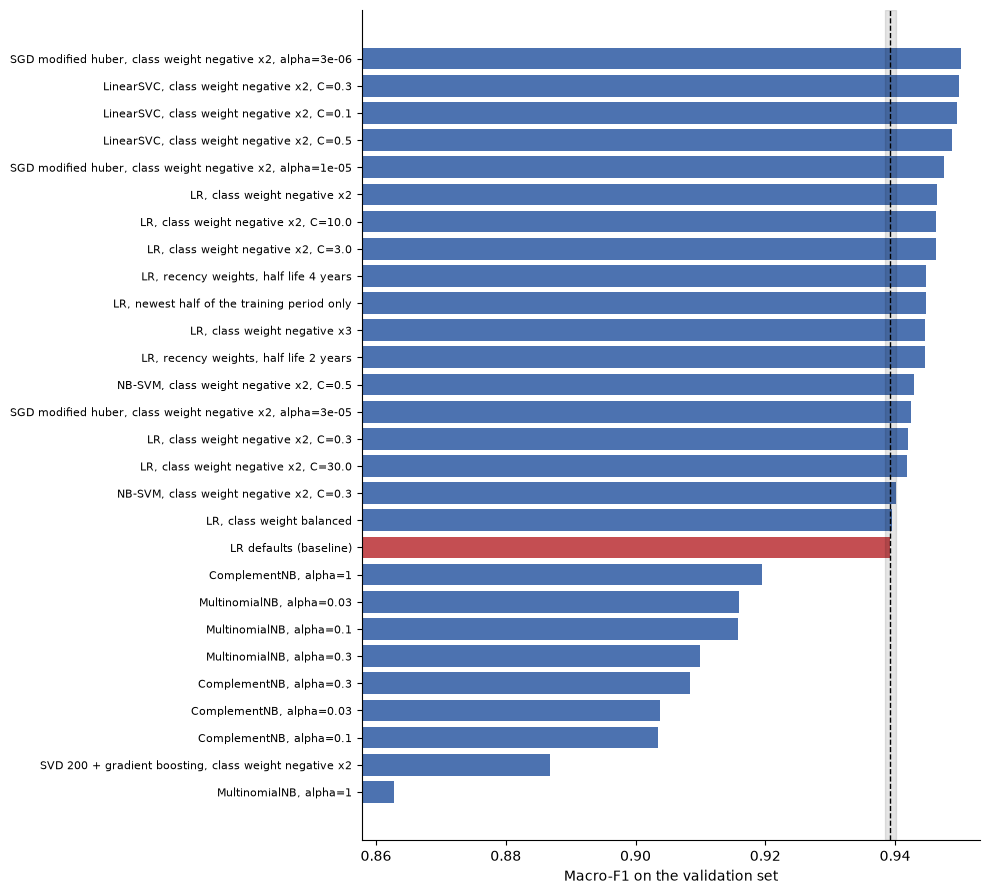

In [84]:
all8 = pd.DataFrame(s8).drop(columns='params').sort_values('macro_f1').reset_index(drop=True)
pos = np.arange(len(all8))
fig, ax = plt.subplots(figsize=(10, 0.28 * len(all8) + 1.2))
ax.barh(pos, all8['macro_f1'], color=[NEG if g == 'baseline' else POS for g in all8['group']])
ax.axvline(BASELINE_F1, color='k', ls='--', lw=1)
ax.axvspan(BASELINE_F1 - TIE, BASELINE_F1 + TIE, color='k', alpha=0.1)
ax.set_yticks(pos, all8['name'], fontsize=8)
ax.set_xlim(all8['macro_f1'].min() - 0.005, all8['macro_f1'].max() + 0.003)
ax.set_xlabel('Macro-F1 on the validation set')
plt.tight_layout()
plt.show()

In [85]:
top = all8[all8['macro_f1'] >= all8['macro_f1'].max() - TIE].sort_values('macro_f1', ascending=False).set_index('name')
top['vs_baseline'] = top['macro_f1'] - BASELINE_F1
print(f"best macro-F1 = {all8['macro_f1'].max():.4f}. Models within the tie threshold of the best ({TIE:.4f}):")
top.drop(columns='group').style.format({c: '{:.4f}' for c in ['accuracy', 'precision_negative', 'recall_negative',
                                                             'f1_negative', 'f1_positive', 'macro_f1']}
                                       | {'vs_baseline': '{:+.4f}'})

best macro-F1 = 0.9501. Models within the tie threshold of the best (0.0009):


,accuracy,precision_negative,recall_negative,f1_negative,f1_positive,macro_f1,seconds,memory_gb,vs_baseline
name,,,,,,,,,
"SGD modified huber, class weight negative x2, alpha=3e-06",0.9674,0.9116,0.9299,0.9207,0.9795,0.9501,20,8.100000,+0.0108
"LinearSVC, class weight negative x2, C=0.3",0.9674,0.9145,0.9261,0.9202,0.9795,0.9499,617,8.100000,+0.0106
"LinearSVC, class weight negative x2, C=0.1",0.9672,0.9127,0.9271,0.9198,0.9794,0.9496,142,8.100000,+0.0103


In [86]:
print('model chosen by the tie rule so far:', best['name'])
print(f"macro-F1 {best['macro_f1']:.4f} against baseline {BASELINE_F1:.4f} ({best['macro_f1'] - BASELINE_F1:+.4f})")

model chosen by the tie rule so far: SGD modified huber, class weight negative x2, alpha=3e-06
macro-F1 0.9501 against baseline 0.9393 (+0.0108)


**Decisions and limits for 8.1.**

**Decisions**
- Class weight: negative x2.
- Logistic regression `C`: the default of 1.
- Classical model: the SGD classifier with the modified Huber loss, `alpha=3e-06` and the weight of negative x2. It has the best score and by far the shortest fit time. LinearSVC ties with it, but is slower.
- Naive Bayes, NB-SVM, gradient boosting and recency weights are not used.
- The best classical model is saved in 8.1.8 and is the classical bar for the transformer models.

**Limits of this search**
- The class weight and `C` were chosen with logistic regression and then reused for LinearSVC and SGD, so the search is one step at a time and not a joint grid.
- The SGD result is one run with one seed. Its spread across seeds is not measured.
- 28 models were compared on the same validation set, so the best score is slightly optimistic. The test set stays untouched.

#### 8.1.8 Saving the Best Classical Model

The models of the search were not kept, because each fit overwrote the previous one. The best model, chosen by the tie rule above, is therefore fitted again with the same settings and the same seed. It is saved together with the vectoriser as one `Pipeline`, so that one file turns raw review text into a prediction.

The cell prints the score of the new fit next to the score from the search. They should be equal, because nothing in the fit is random except the fixed seed. The next cell loads the file again and checks that it gives the same predictions on 20,000 validation reviews. The refit takes about as long as the search fit of the same model (20 seconds for the SGD classifier).

In [90]:
def build_classical(params):
    cw = params.get('class_weight')
    if params.get('model') == 'svc':
        return LinearSVC(C=params['C'], class_weight=cw, random_state=SEED)
    if params.get('model') == 'sgd':
        return SGDClassifier(loss='modified_huber', alpha=params['alpha'], class_weight=cw,
                             max_iter=50, tol=1e-4, random_state=SEED)
    if 'model' not in params and 'recency' not in params:
        return LogisticRegression(max_iter=1000, class_weight=cw, C=params['C'])
    raise ValueError(f"no saved recipe for {best['name']}")

def file_slug(params):
    kind = params.get('model', 'lr')
    value = params['alpha'] if kind == 'sgd' else params['C']
    return f"{kind}_{'alpha' if kind == 'sgd' else 'C'}{value:g}"

t0 = time.time()
best_clf = build_classical(best['params']).fit(Xt_base, y_train)
best_pipeline = Pipeline([('tfidf', vec_base), ('model', best_clf)])
best_pred = best_clf.predict(Xv_base)
refit_f1 = f1_score(y_valid, best_pred, average='macro')

best_path = MODEL_DIR / f"classical_best_{file_slug(best['params'])}.joblib"
joblib.dump(best_pipeline, best_path)

print(f"model: {best['name']}")
print(f"macro-F1 in the search {best['macro_f1']:.4f}, after the refit {refit_f1:.4f}, refit took {time.time() - t0:.0f} s")
print(f"saved to {best_path} ({best_path.stat().st_size / 1e6:.0f} MB)")

model: SGD modified huber, class weight negative x2, alpha=3e-06
macro-F1 in the search 0.9501, after the refit 0.9501, refit took 26 s
saved to models/classical_best_sgd_alpha3e-06.joblib (41 MB)


In [91]:
loaded = joblib.load(best_path)
check = valid.iloc[:20_000]
loaded_pred = loaded.predict(join_title(check))
assert np.array_equal(loaded_pred, best_pred[:20_000])
print(f'reloaded model gives the same {len(check):,} predictions as the fitted model')
print('macro-F1 on these reviews:', round(f1_score(y_valid[:20_000], loaded_pred, average='macro'), 4))

reloaded model gives the same 20,000 predictions as the fitted model
macro-F1 on these reviews: 0.9476


#### 8.1.9 Summary of Classical Models

| Model | Macro-F1 | Negative recall | Negative precision | Fit time | Role |
|---|---|---|---|---|---|
| Baseline, logistic regression defaults | 0.9393 | 0.8718 | 0.9352 | 104 s | Bar from Section 7 |
| Logistic regression, negative x2 | 0.9465 | 0.9252 | 0.9049 | 103 s | Class weight helps |
| LinearSVC, negative x2, `C=0.1` | 0.9496 | 0.9271 | 0.9127 | 142 s | Ties with the best |
| LinearSVC, negative x2, `C=0.3` | 0.9499 | 0.9261 | 0.9145 | 617 s | Ties with the best, slow |
| **SGD modified Huber, negative x2, `alpha=3e-06`** | **0.9501** | **0.9299** | **0.9116** | **20 s** | **Best classical model, saved** |
| NB-SVM, negative x2, `C=0.5` | 0.9429 | 0.9143 | 0.9041 | 35 s | Below logistic regression |
| ComplementNB, `alpha=1` | 0.9195 | 0.8853 | 0.8596 | 1 s | Fast but weak |
| SVD 200 and gradient boosting | 0.8868 | 0.8265 | 0.8135 | 1,738 s | Not competitive |

**Bar for the transformer models:** macro-F1 of 0.9501 on the validation set (+0.0108 over the Section 7 baseline), with a tie threshold of 0.0009. The transformer part is compared with this model and with the baseline.

**What the classical search showed**
- The gain over the baseline comes from two things: the class weight of negative x2, which trades some precision for recall, and a linear model with a good regularisation level (SGD or LinearSVC), which adds about 0.0036 on top.
- Recent reviews, trees on compressed features and Naive Bayes do not help on this data.
- The best model is also the cheapest of the strong ones, which matters when the data grows.